In [62]:
import numpy as np
import pandas as pd

# 1. Caricamento del dataset
df = pd.read_csv("../data/processed/dataset.csv")

# 2. Alias automatici per evitare KeyError sui nomi delle feature
if "subreddits_obs_conspiracy_score" in df.columns:
    df["subreddit_obs_conspiracy_score"] = df["subreddits_obs_conspiracy_score"]
if "growing_exclusivity_contributions" in df.columns:
    df["growing_exclusibity_contributions"] = df[
        "growing_exclusivity_contributions"
    ]

# 3. Creazione sicura della colonna di raggruppamento (gestisce bool, stringhe 'True'/'False', 1/0)
is_anchor_clean = (
    df["is_anchor"].astype(str).str.strip().str.lower().isin(["true", "1", "t"])
)
df["group_label"] = np.where(is_anchor_clean, "Anchor", "Non-Anchor")

print("Dataset pronto!")
print(df["group_label"].value_counts())

Dataset pronto!
group_label
Anchor        98
Non-Anchor    98
Name: count, dtype: int64


In [63]:
from matplotlib.ticker import ScalarFormatter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
import seaborn as sns

PALETTE = {
    "Non-Anchor": "#2b5c8f",
    "Anchor": "#d95f02",
}


def plot_feature_grid(
    df,
    features,
    title_group,
    n_cols=2,
    custom_xlims=None,
    log_features=None,
    robust_xlim=True,
    bw_adjust=0.85,
    show_stats=True,
    show_rug=True,
):
    if custom_xlims is None:
        custom_xlims = {}
    if log_features is None:
        log_features = []

    plot_df = df.copy()

    # Creazione sicura della label di raggruppamento
    if "group_label" not in plot_df.columns:
        is_anchor_clean = (
            plot_df["is_anchor"]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "t"])
        )
        plot_df["group_label"] = np.where(
            is_anchor_clean, "Anchor", "Non-Anchor"
        )

    valid_features = [f for f in features if f in plot_df.columns]
    if not valid_features:
        print("Nessuna delle feature specificate è presente nel DataFrame.")
        return

    n_features = len(valid_features)
    n_rows = int(np.ceil(n_features / n_cols))

    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(7.0 * n_cols, 4.4 * n_rows),
        dpi=150,
    )

    if n_features == 1:
        axes = np.array([axes])
    else:
        axes = np.array(axes).flatten()

    for i, feature in enumerate(valid_features):
        ax = axes[i]
        is_log = feature in log_features

        # Gestione trasformazione logaritmica se richiesta
        if is_log:
            temp_col = f"{feature}_log10"
            plot_df[temp_col] = np.log10(np.maximum(plot_df[feature], 0) + 1)
            plot_var = temp_col
            clip_param = (0, None)
        else:
            plot_var = feature
            min_val = plot_df[plot_var].dropna().min()
            clip_param = (0, None) if min_val >= 0 else None

        # 1. Tracciamento KDE
        sns.kdeplot(
            data=plot_df,
            x=plot_var,
            hue="group_label",
            palette=PALETTE,
            common_norm=False,
            fill=True,
            alpha=0.28,
            linewidth=2.0,
            cut=0,
            clip=clip_param,
            bw_adjust=bw_adjust,
            ax=ax,
            legend=False,
        )

        # 2. Rugplot alla base (evidenzia i singoli utenti campionati)
        if show_rug:
            sns.rugplot(
                data=plot_df,
                x=plot_var,
                hue="group_label",
                palette=PALETTE,
                height=0.06,
                alpha=0.75,
                lw=1.1,
                ax=ax,
                legend=False,
            )

        # 3. Mediane calcolate e formattate per la legenda
        medians = plot_df.groupby("group_label")[plot_var].median(
            numeric_only=True
        )
        orig_medians = plot_df.groupby("group_label")[feature].median(
            numeric_only=True
        )

        for group_name in ["Non-Anchor", "Anchor"]:
            if group_name in medians and pd.notna(medians[group_name]):
                m_plot = medians[group_name]
                m_orig = orig_medians[group_name]

                # Formattazione adattiva della mediana in base alla scala
                if is_log:
                    label_str = f"{group_name} (Med: {m_orig:.0f})"
                elif abs(m_orig) < 0.005 and m_orig != 0:
                    label_str = f"{group_name} (Med: {m_orig:.4f})"
                else:
                    label_str = f"{group_name} (Med: {m_orig:.3f})"

                ax.axvline(
                    m_plot,
                    color=PALETTE[group_name],
                    linestyle=":",
                    linewidth=1.8,
                    alpha=0.95,
                    label=label_str,
                )

        ax.legend(
            title="Gruppo (N=122)",
            frameon=True,
            facecolor="white",
            edgecolor="#ced4da",
            fontsize=9,
        )

        # 4. Calcolo formale del Test di Mann-Whitney U ed Effect Size
        clean_title = feature.replace("_", " ").title()
        if show_stats:
            s_non = plot_df[plot_df["group_label"] == "Non-Anchor"][
                feature
            ].dropna()
            s_anc = plot_df[plot_df["group_label"] == "Anchor"][
                feature
            ].dropna()
            u_stat, pval = mannwhitneyu(s_anc, s_non, alternative="two-sided")
            # Rank-biserial correlation come effect size per Mann-Whitney
            r_rb = abs(1 - (2 * u_stat) / (len(s_anc) * len(s_non)))

            if pval < 0.001:
                p_text = "p < 0.001***"
            elif pval < 0.01:
                p_text = f"p = {pval:.3f}**"
            elif pval < 0.05:
                p_text = f"p = {pval:.3f}*"
            else:
                p_text = f"p = {pval:.2f} (n.s.)"

            ax.set_title(clean_title, fontsize=12, fontweight="bold", pad=15)
            ax.text(
                0.5,
                1.02,
                f"Mann-Whitney U: {p_text}  |  Effect Size (r): {r_rb:.2f}",
                transform=ax.transAxes,
                ha="center",
                fontsize=9.5,
                color="#333333",
                style="italic",
            )
        else:
            ax.set_title(clean_title, fontsize=12, fontweight="bold", pad=8)

        # 5. Gestione Asse X (Custom, Logaritmico o Percentile Robusto)
        if feature in custom_xlims:
            ax.set_xlim(custom_xlims[feature])
        elif is_log:
            max_val_log = plot_df[plot_var].max()
            max_t = int(np.floor(max_val_log))
            ticks = list(range(0, max_t + 1))
            tick_labels = [
                "0"
                if t == 0
                else (
                    "10"
                    if t == 1
                    else ("100" if t == 2 else f"{10**(t-3)}k")
                )
                for t in ticks
            ]
            ax.set_xticks(ticks)
            ax.set_xticklabels(tick_labels)
            ax.set_xlim(0, max_val_log * 1.05)
        elif robust_xlim:
            s = plot_df[feature].dropna()
            min_v = s.min()
            max_v = s.max()
            q98 = s.quantile(0.98)
            if max_v > 1.3 * q98 and q98 > min_v:
                right_lim = q98 + (q98 - min_v) * 0.05
            else:
                right_lim = max_v + (max_v - min_v) * 0.02
            left_lim = min_v if min_v >= 0 else s.quantile(0.01)
            ax.set_xlim(left=left_lim, right=right_lim)

        if is_log:
            ax.set_xlabel("Punteggio (Scala Logaritmica)", fontsize=10)
        else:
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits((-2, 3))
            ax.xaxis.set_major_formatter(formatter)
            ax.set_xlabel("Valore", fontsize=10)

        ax.set_ylabel("Densità", fontsize=10)
        ax.grid(True, axis="y", alpha=0.5, linestyle="--")
        sns.despine(ax=ax, top=True, right=True)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(title_group, fontsize=15, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

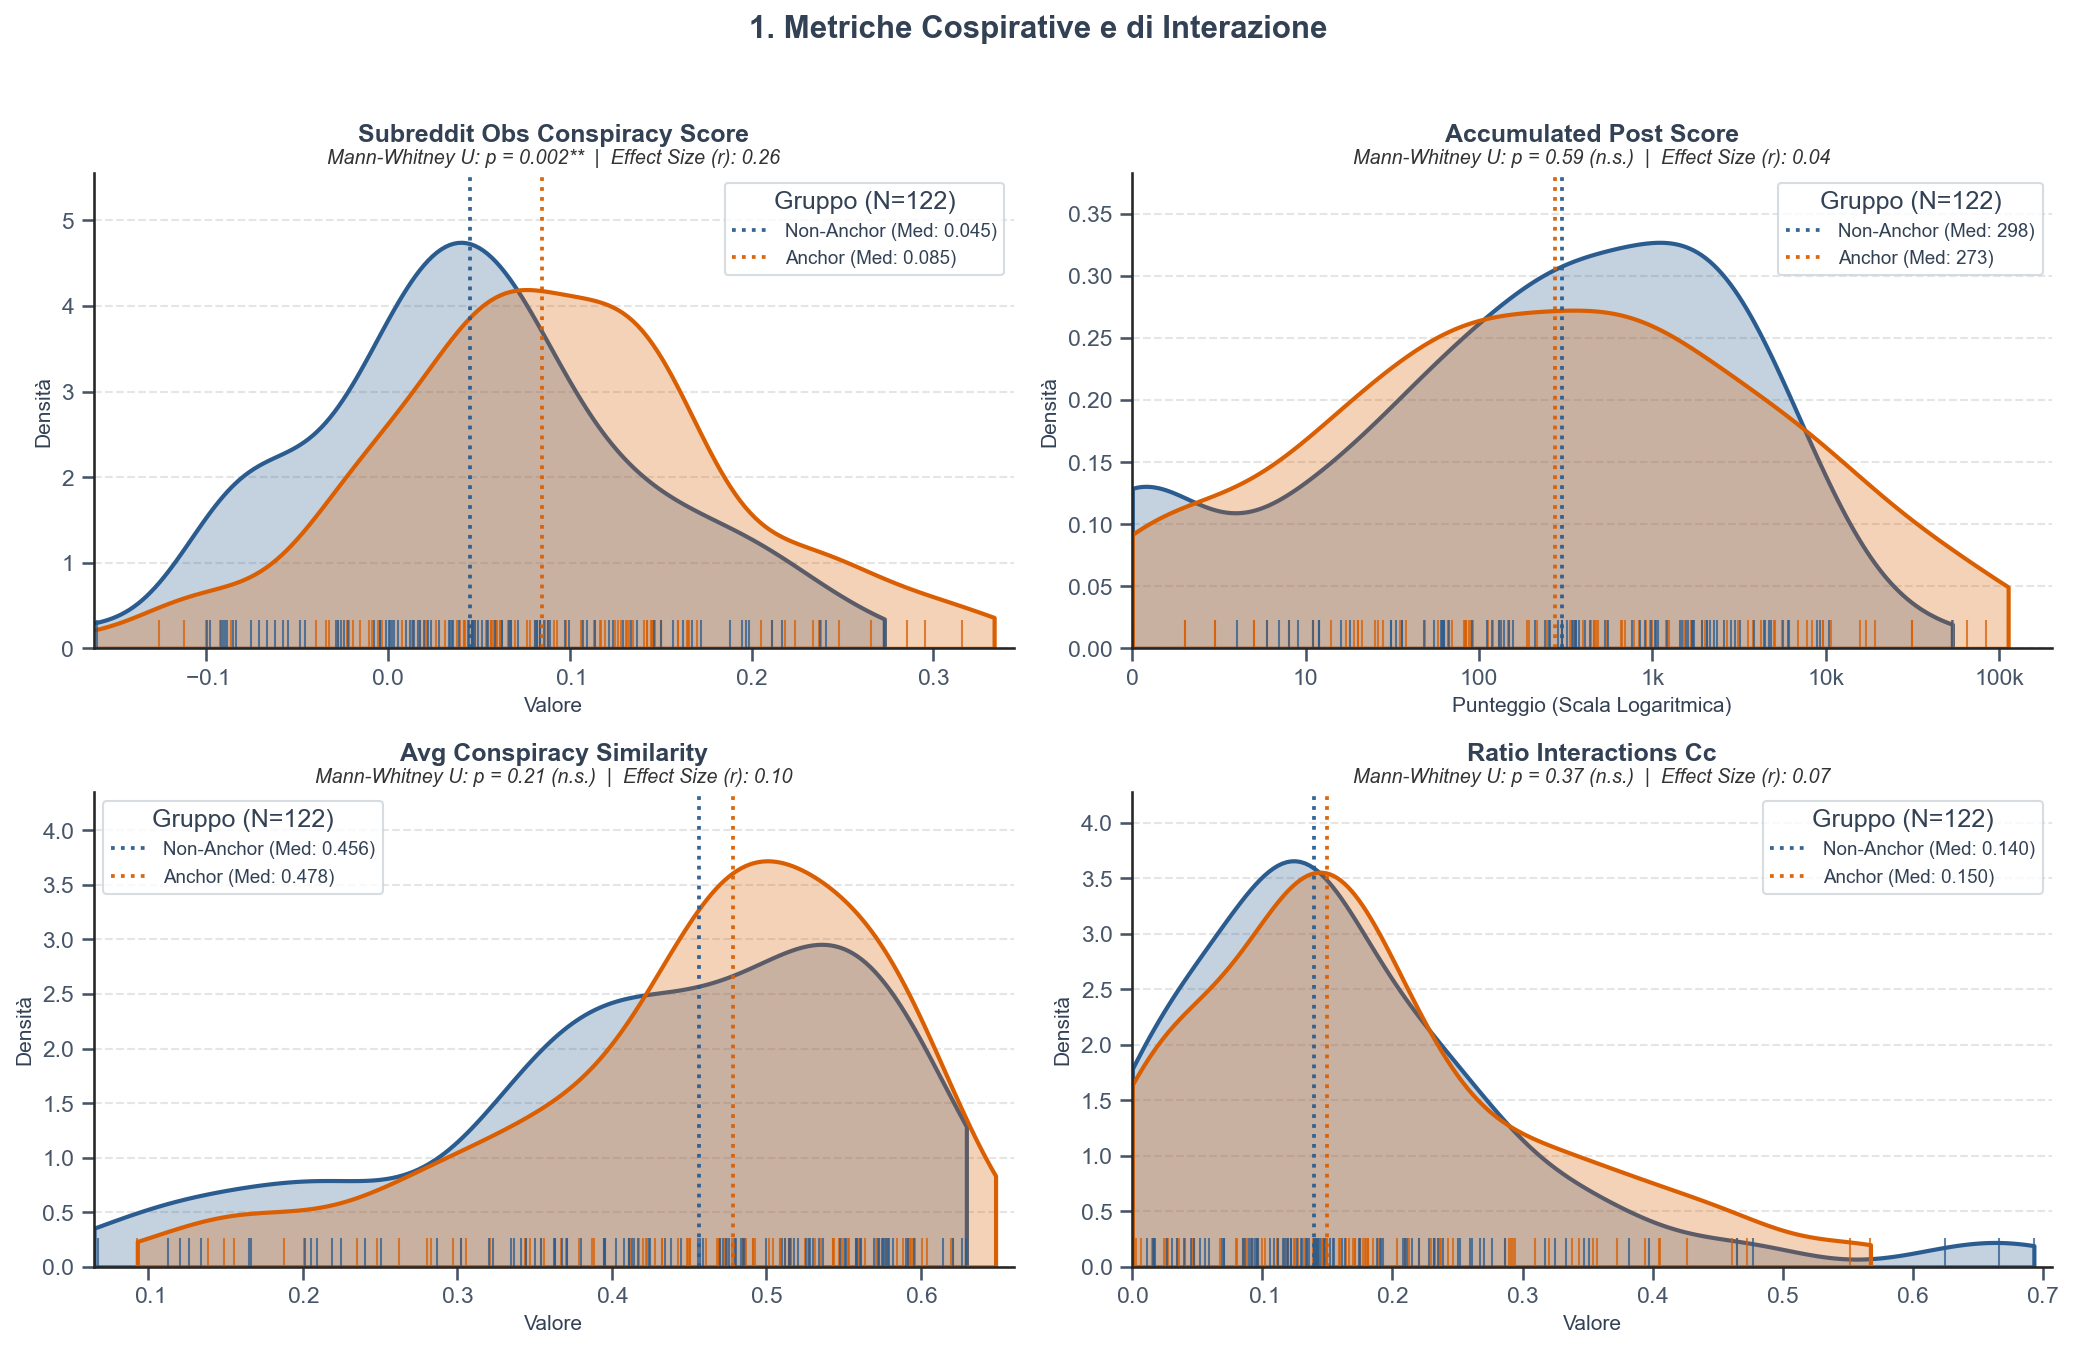

In [64]:
features_conspiracy = [
    "subreddit_obs_conspiracy_score",
    "accumulated_post_score",
    "avg_conspiracy_similarity",
    "ratio_interactions_cc",
]

# accumulated_post_score plottato in scala logaritmica con etichette chiare (0, 10, 100, 1k, 10k, 100k)
plot_feature_grid(
    df=df,
    features=features_conspiracy,
    title_group="1. Metriche Cospirative e di Interazione",
    log_features=["accumulated_post_score"],
)

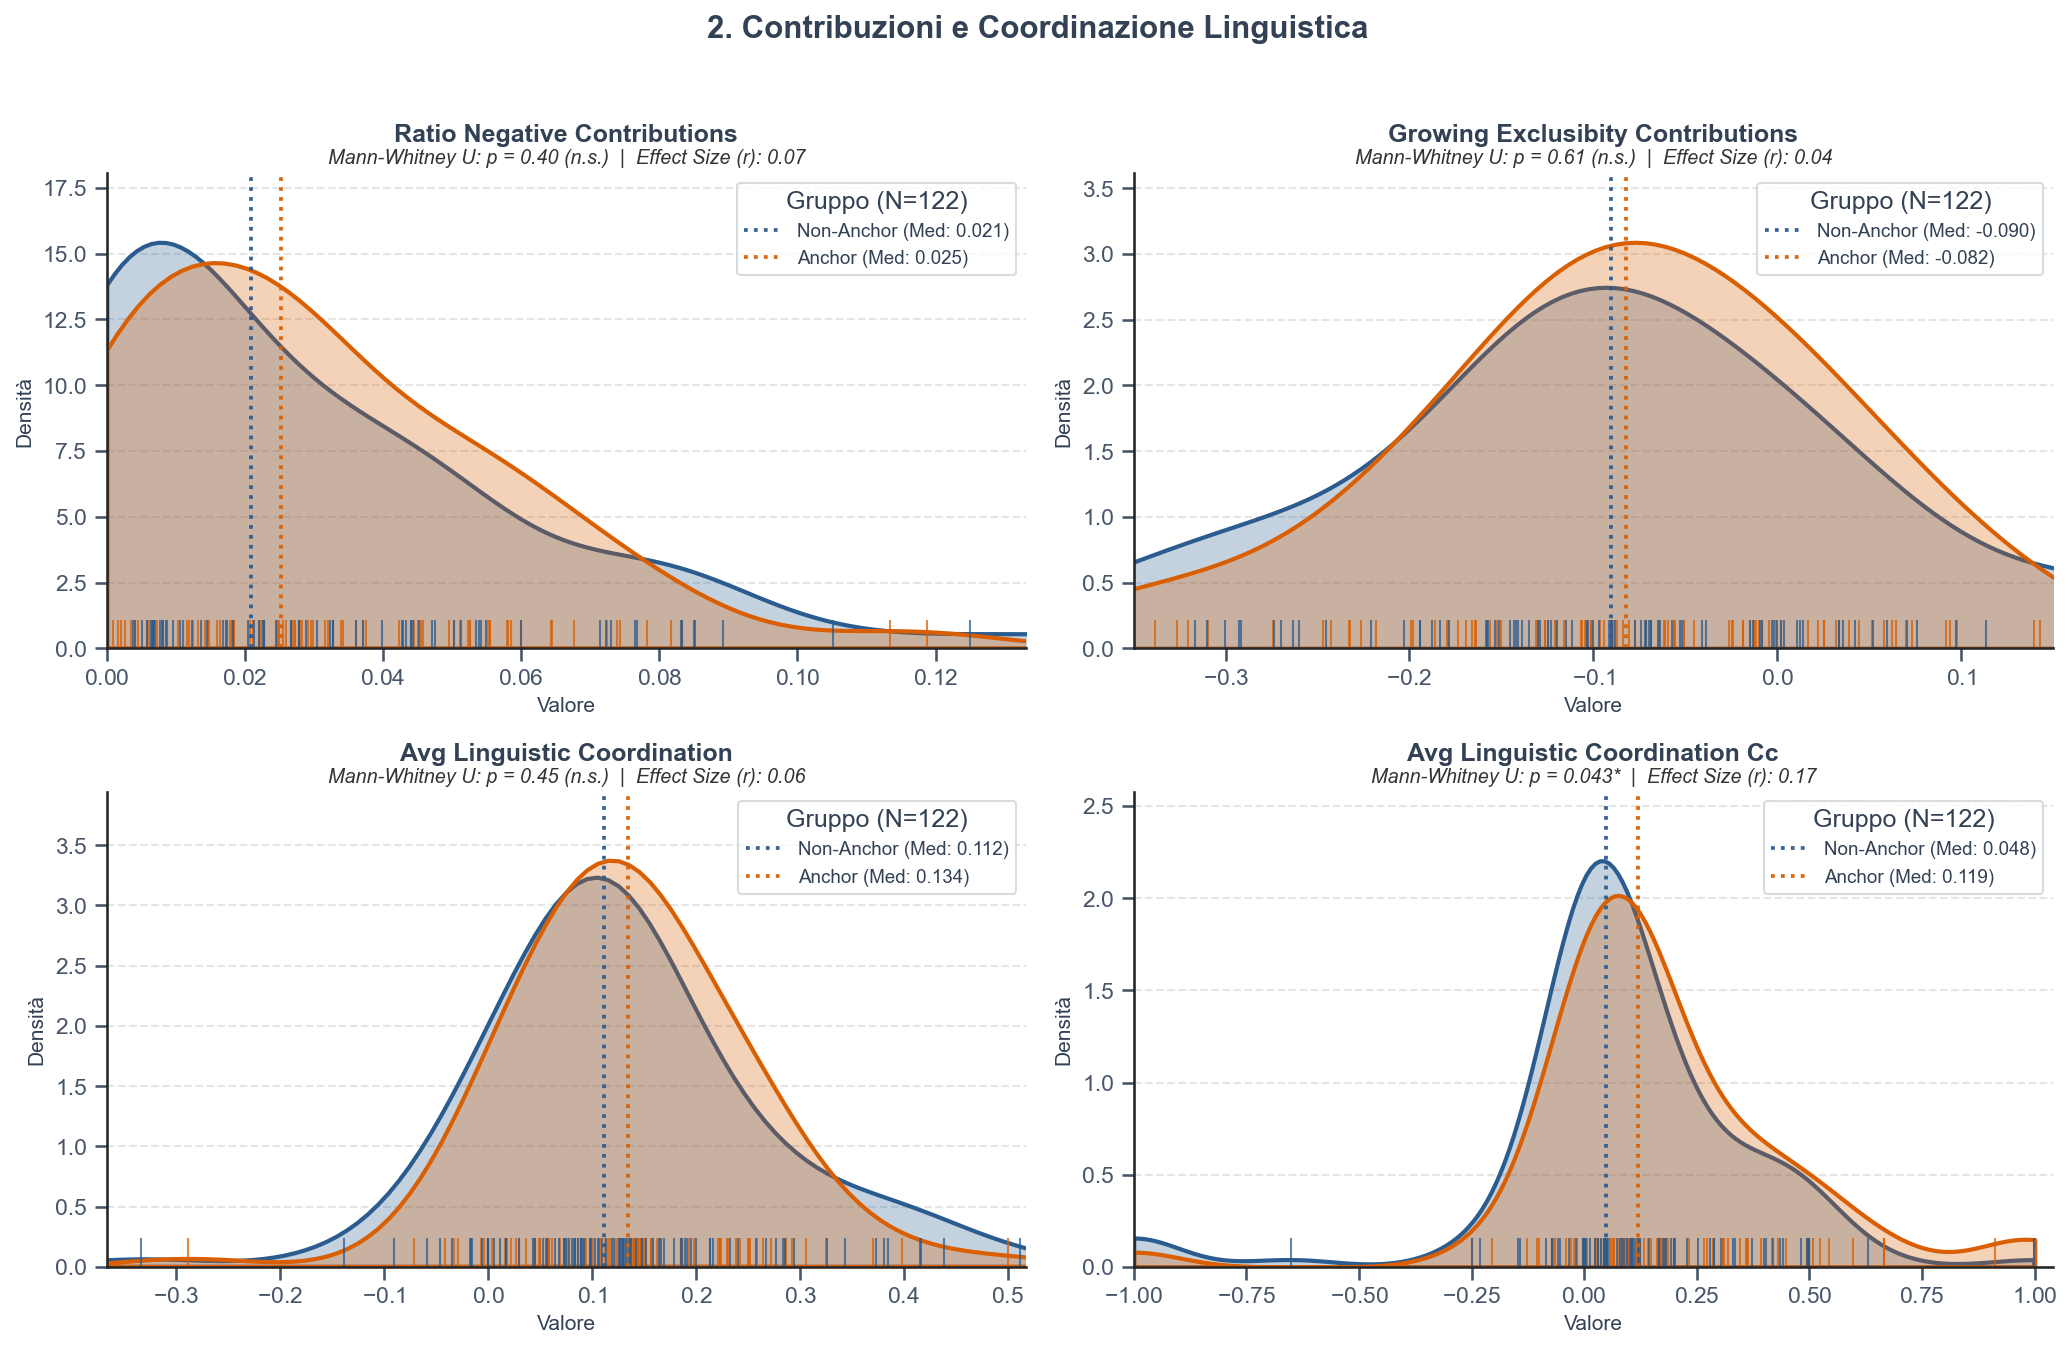

In [65]:
features_contributions = [
    "ratio_negative_contributions",
    "growing_exclusibity_contributions",
    "avg_linguistic_coordination",
    "avg_linguistic_coordination_cc",
]

# Zoom mirato sull'intervallo in cui risiede il 90% della densità per growing exclusivity
plot_feature_grid(
    df=df,
    features=features_contributions,
    title_group="2. Contribuzioni e Coordinazione Linguistica",
    custom_xlims={"growing_exclusibity_contributions": (-0.35, 0.15)},
)

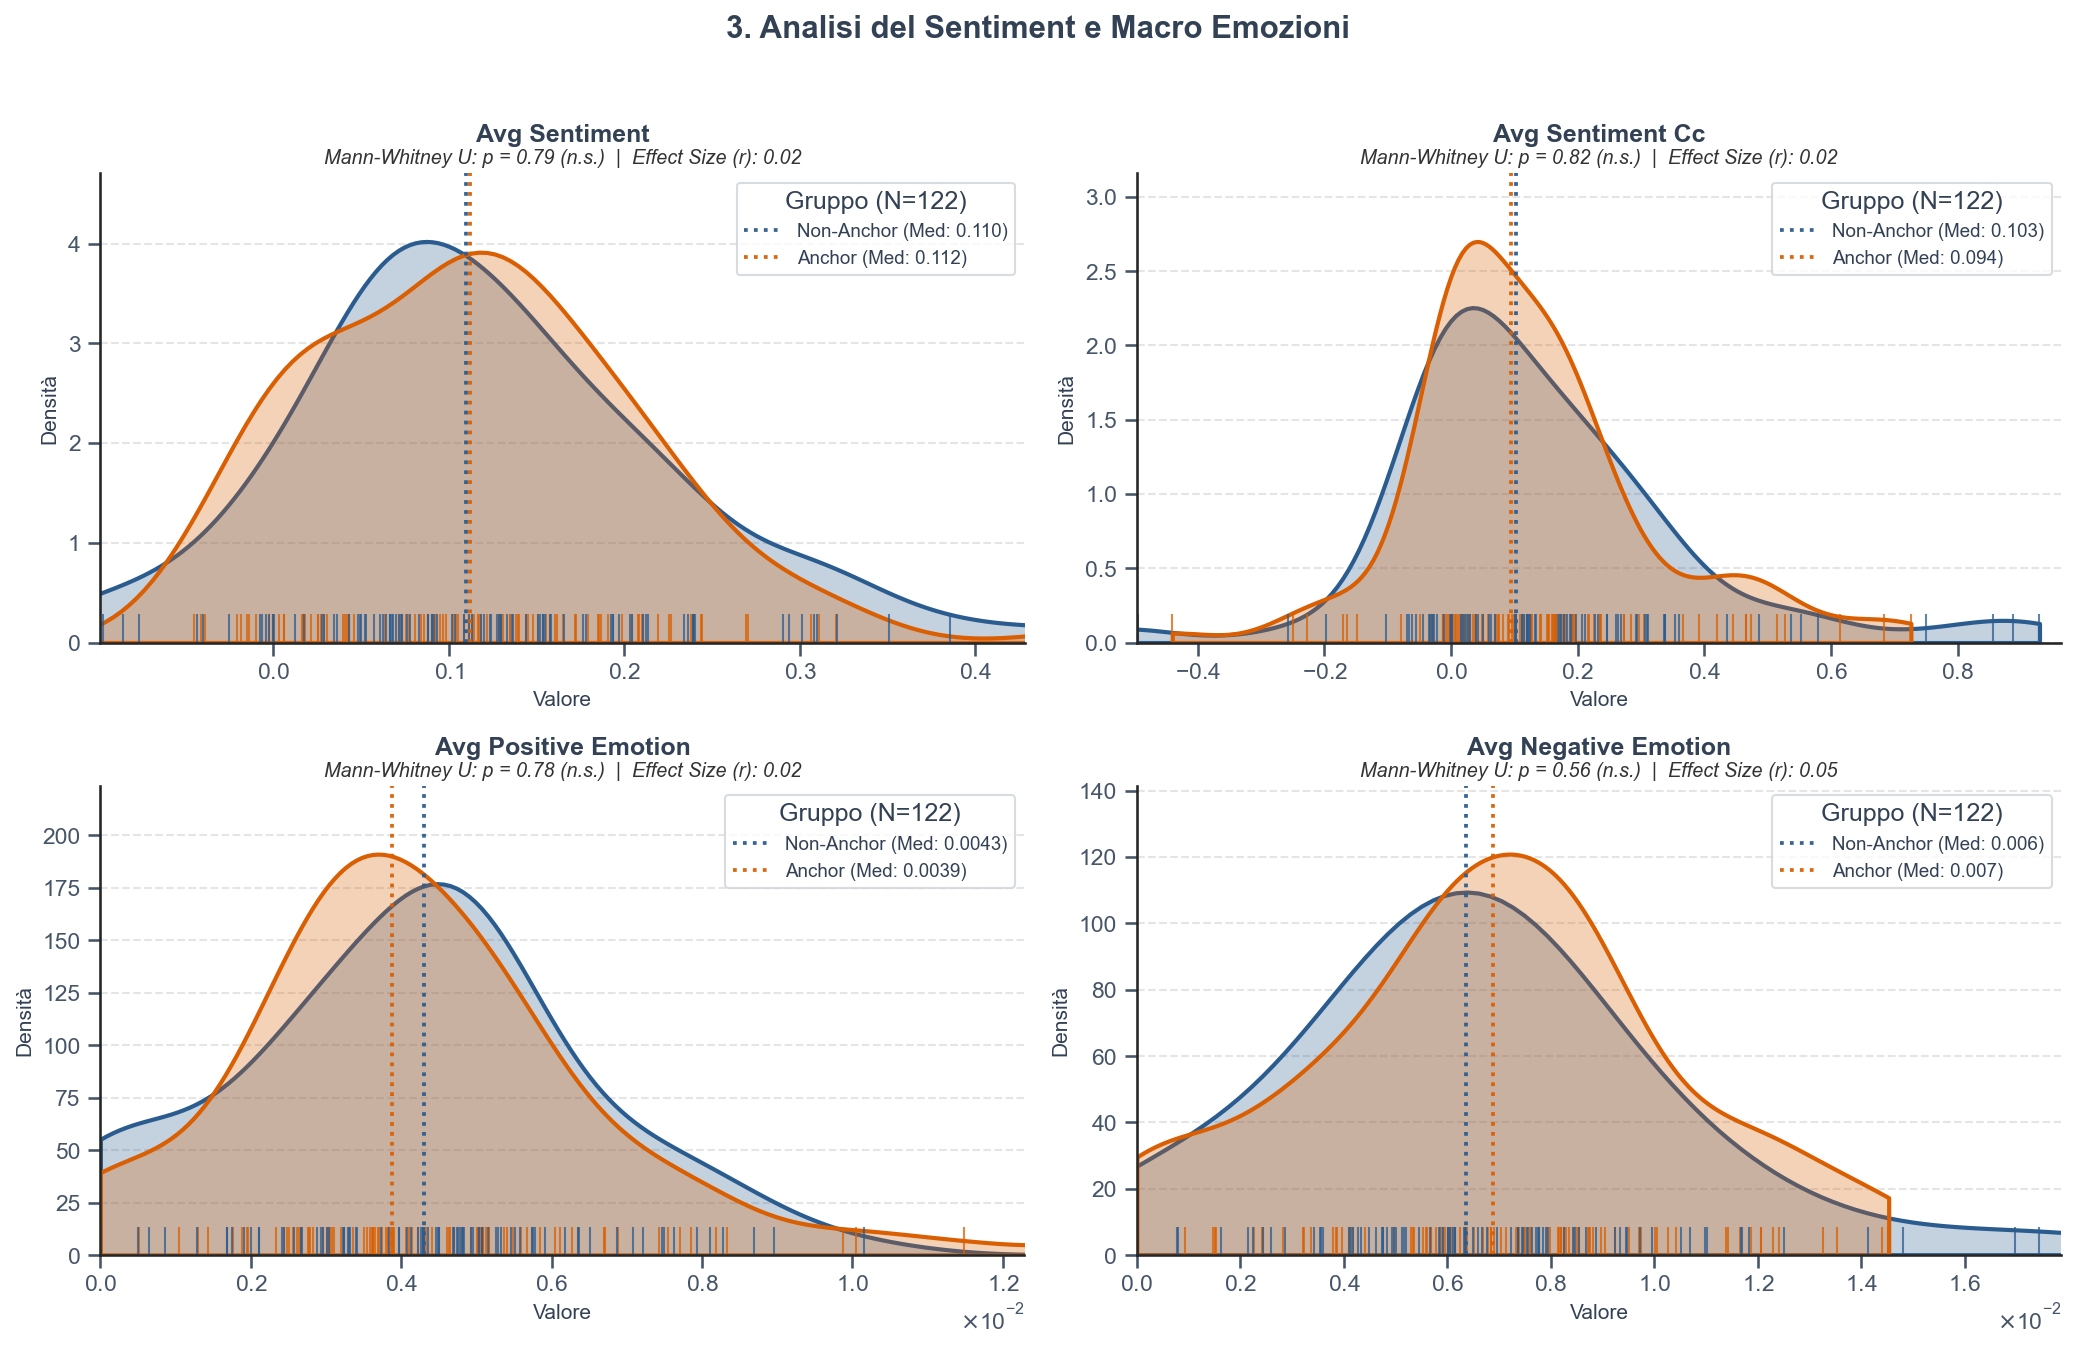

In [66]:
features_sentiment = [
    "avg_sentiment",
    "avg_sentiment_cc",
    "avg_positive_emotion",
    "avg_negative_emotion",
]

plot_feature_grid(
    df, features_sentiment, "3. Analisi del Sentiment e Macro Emozioni"
)

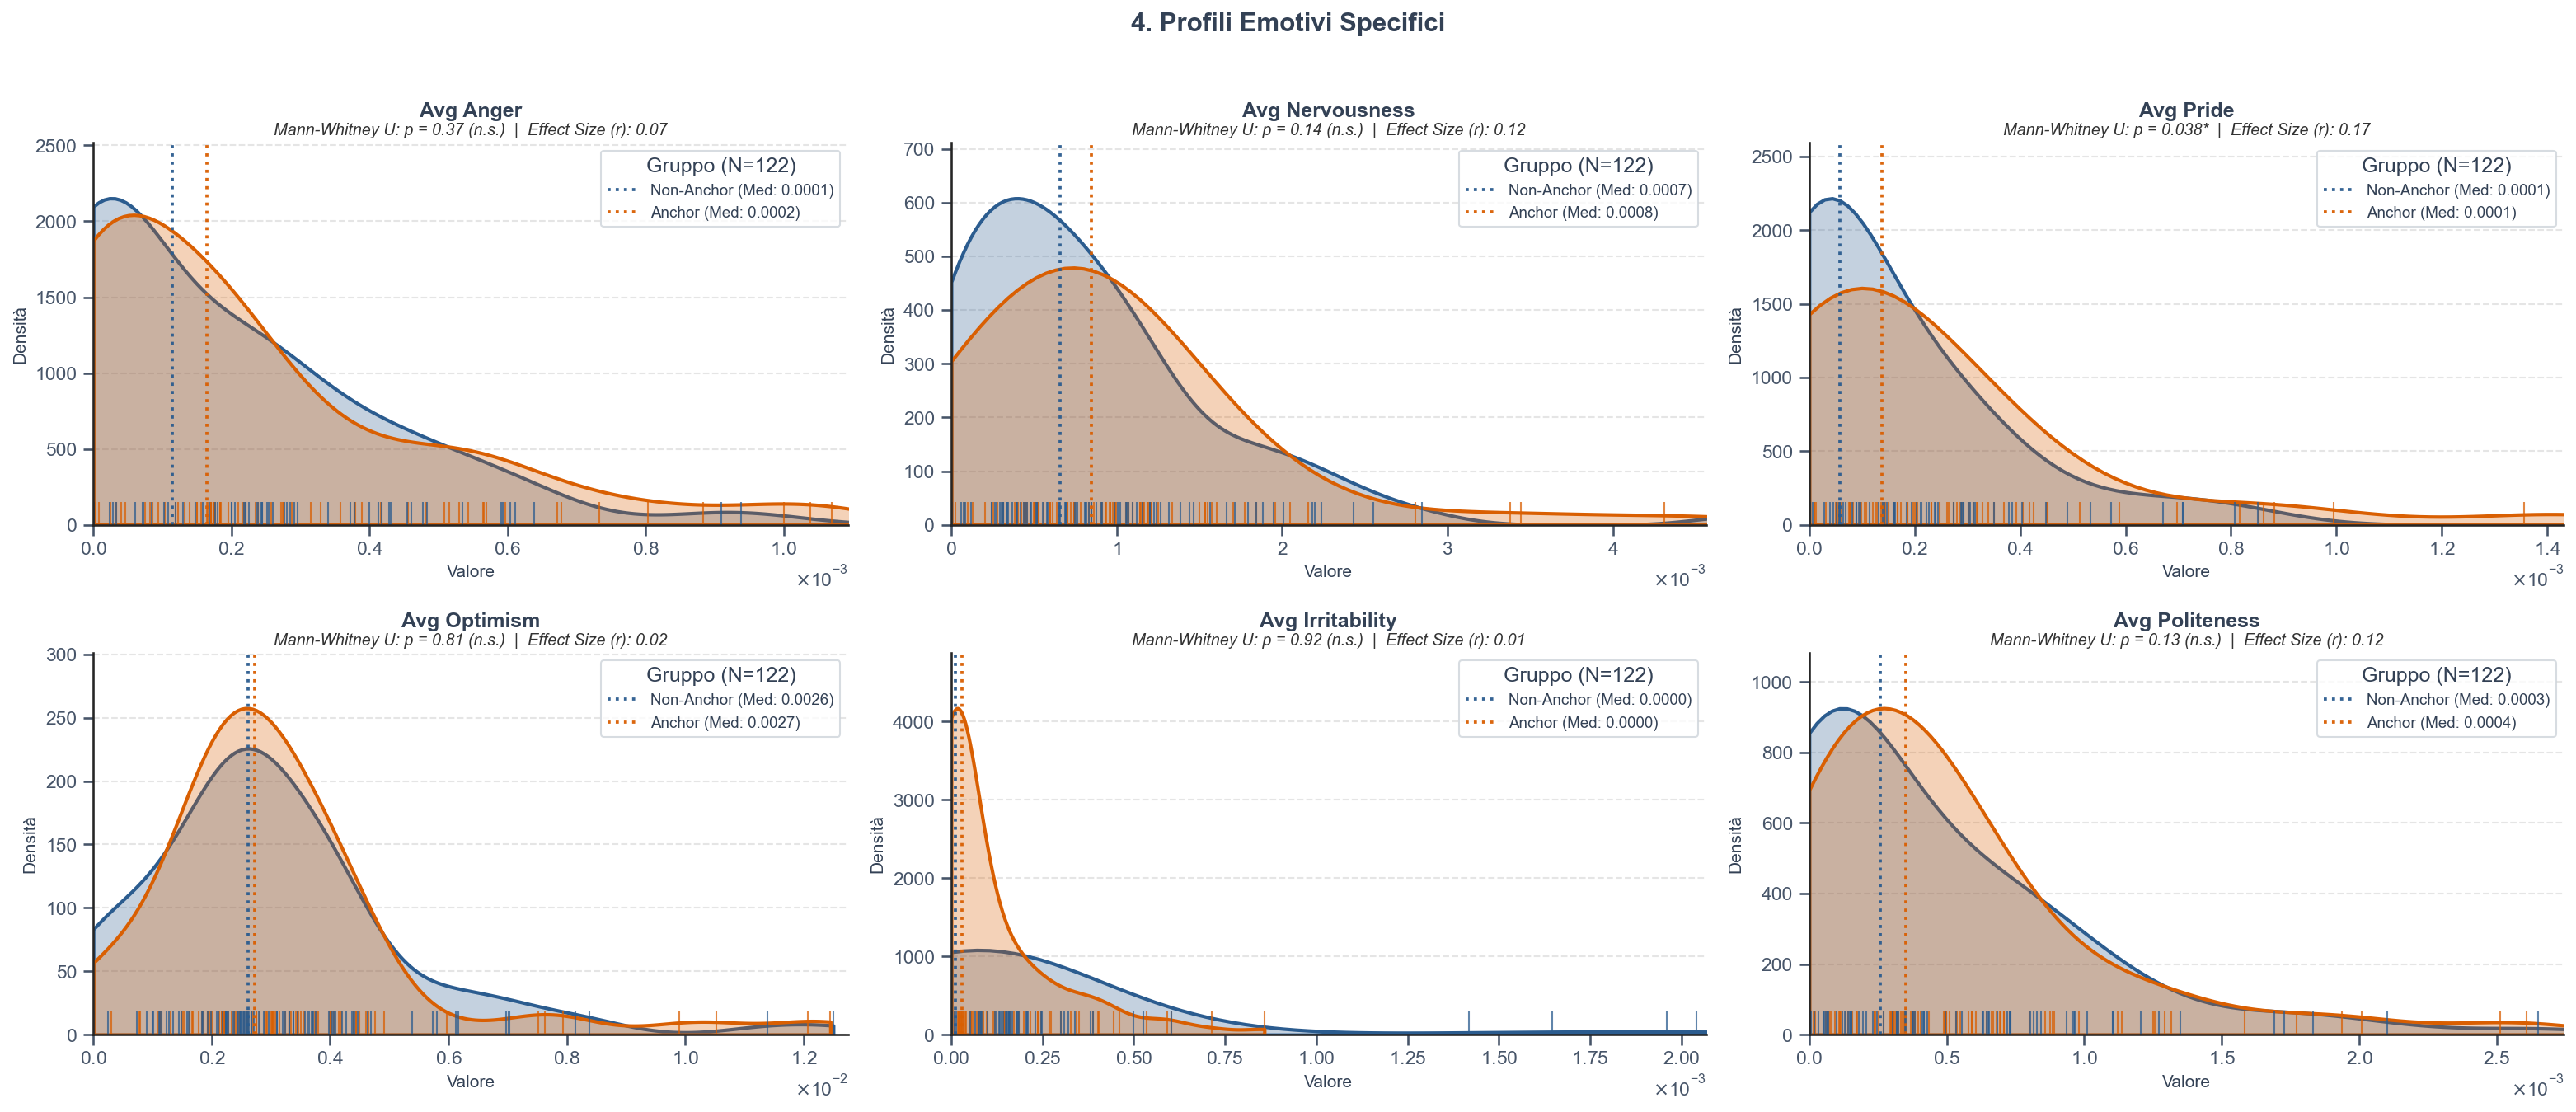

In [67]:
features_emotions = [
    "avg_anger",
    "avg_nervousness",
    "avg_pride",
    "avg_optimism",
    "avg_irritability",
    "avg_politeness",
]

plot_feature_grid(
    df, features_emotions, "4. Profili Emotivi Specifici", n_cols=3
)

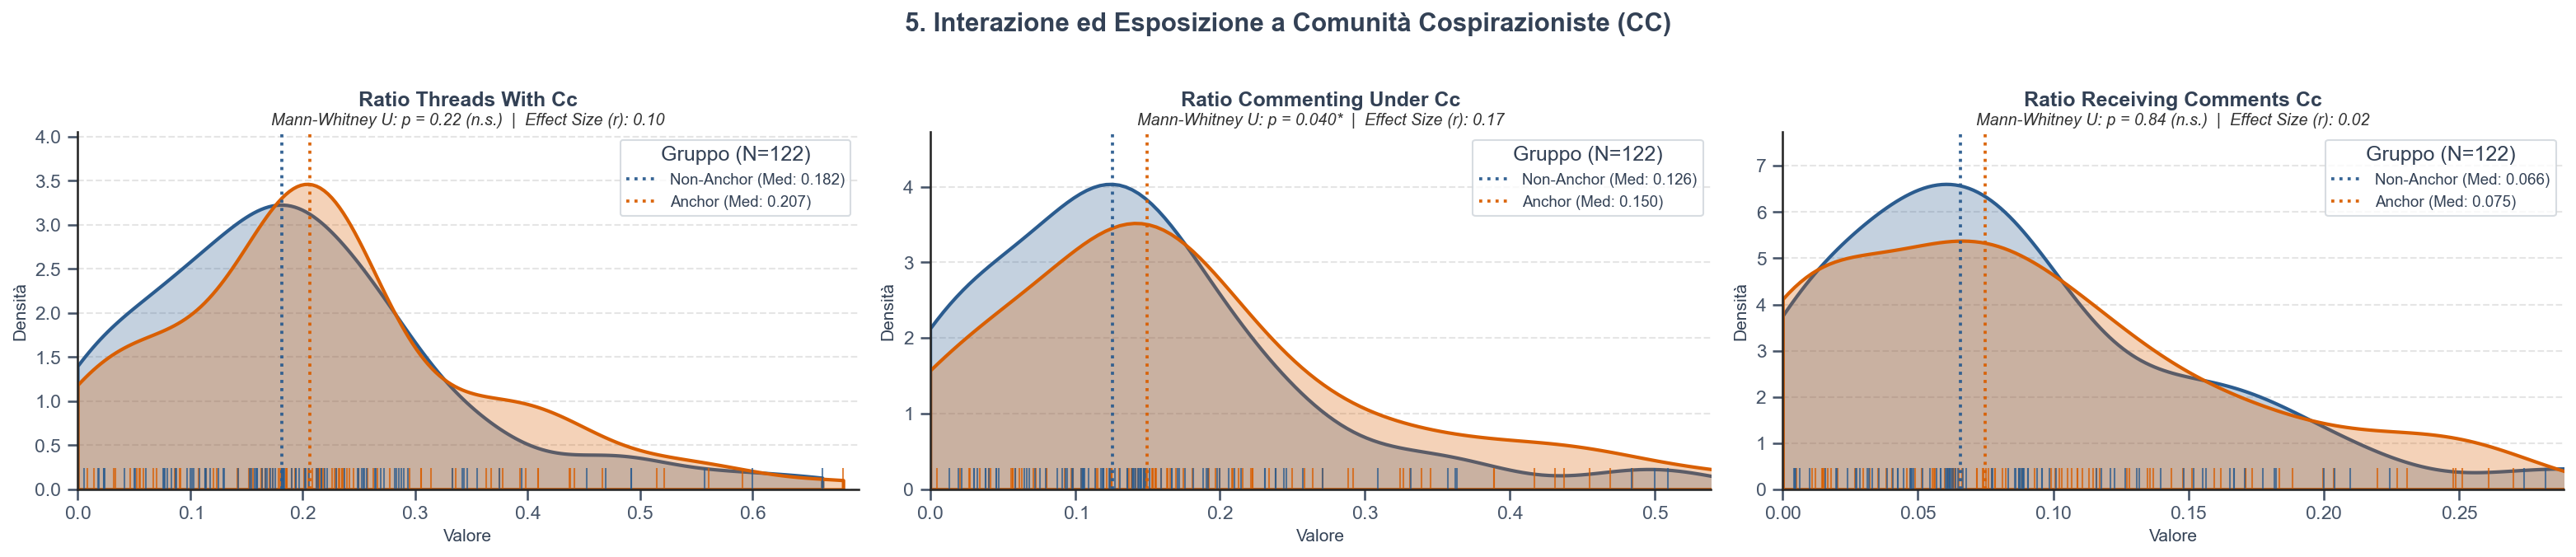

In [68]:
features_cc_interactions = [
    "ratio_threads_with_cc",
    "ratio_commenting_under_cc",
    "ratio_receiving_comments_cc",
]

plot_feature_grid(
    df=df,
    features=features_cc_interactions,
    title_group="5. Interazione ed Esposizione a Comunità Cospirazioniste (CC)",
    n_cols=3,
)

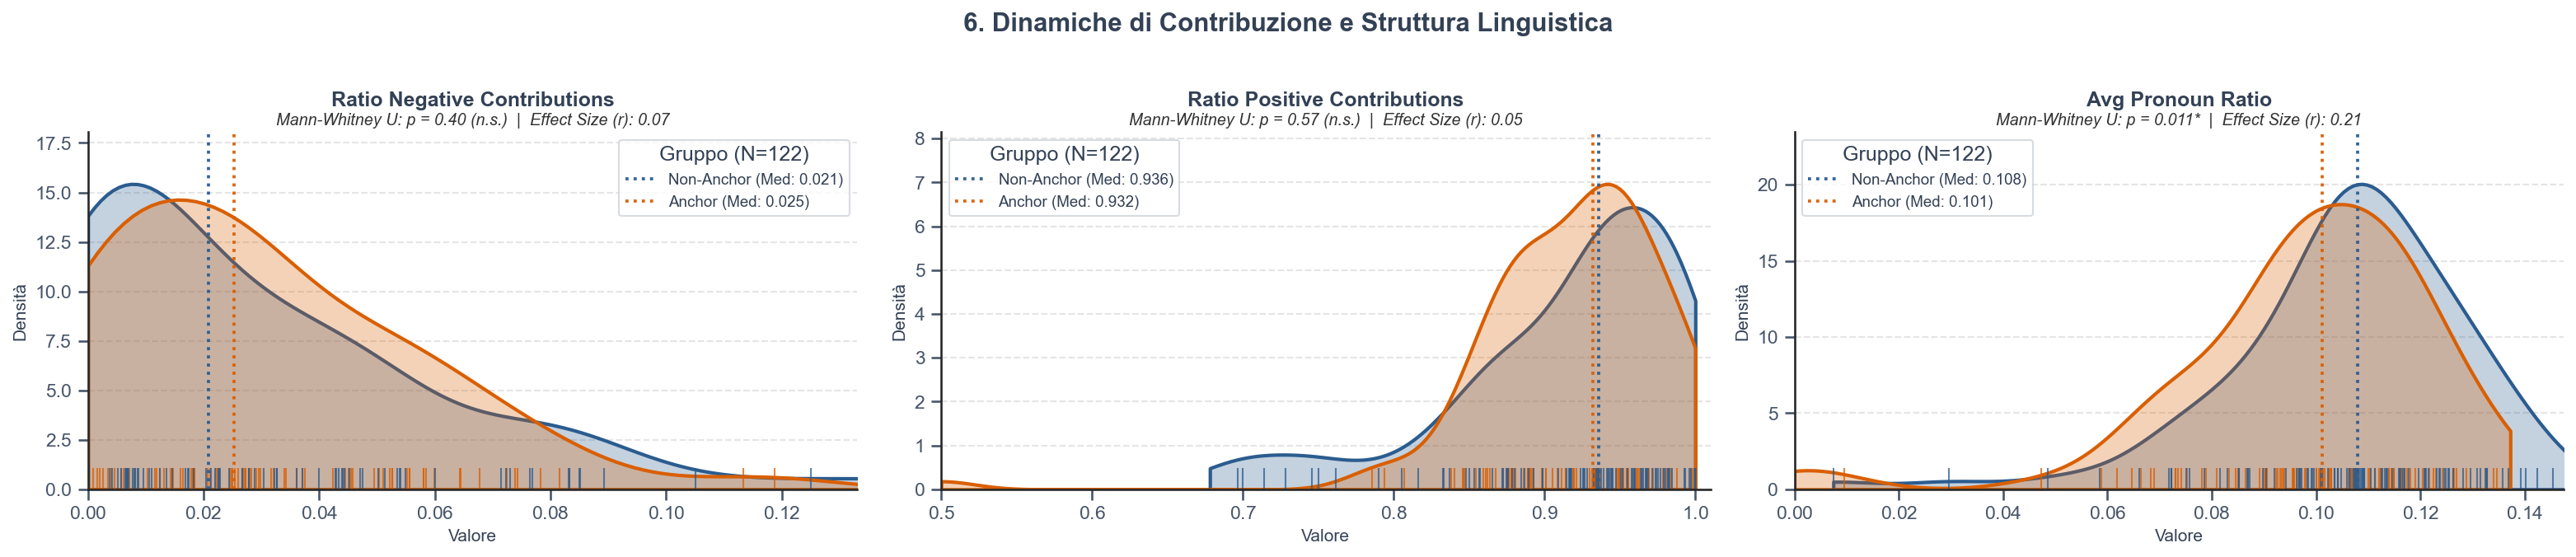

In [69]:
features_contributions_valence = [
    "ratio_negative_contributions",
    "ratio_positive_contributions",
    "avg_pronoun_ratio",
]

plot_feature_grid(
    df=df,
    features=features_contributions_valence,
    title_group="6. Dinamiche di Contribuzione e Struttura Linguistica",
    n_cols=3,
)

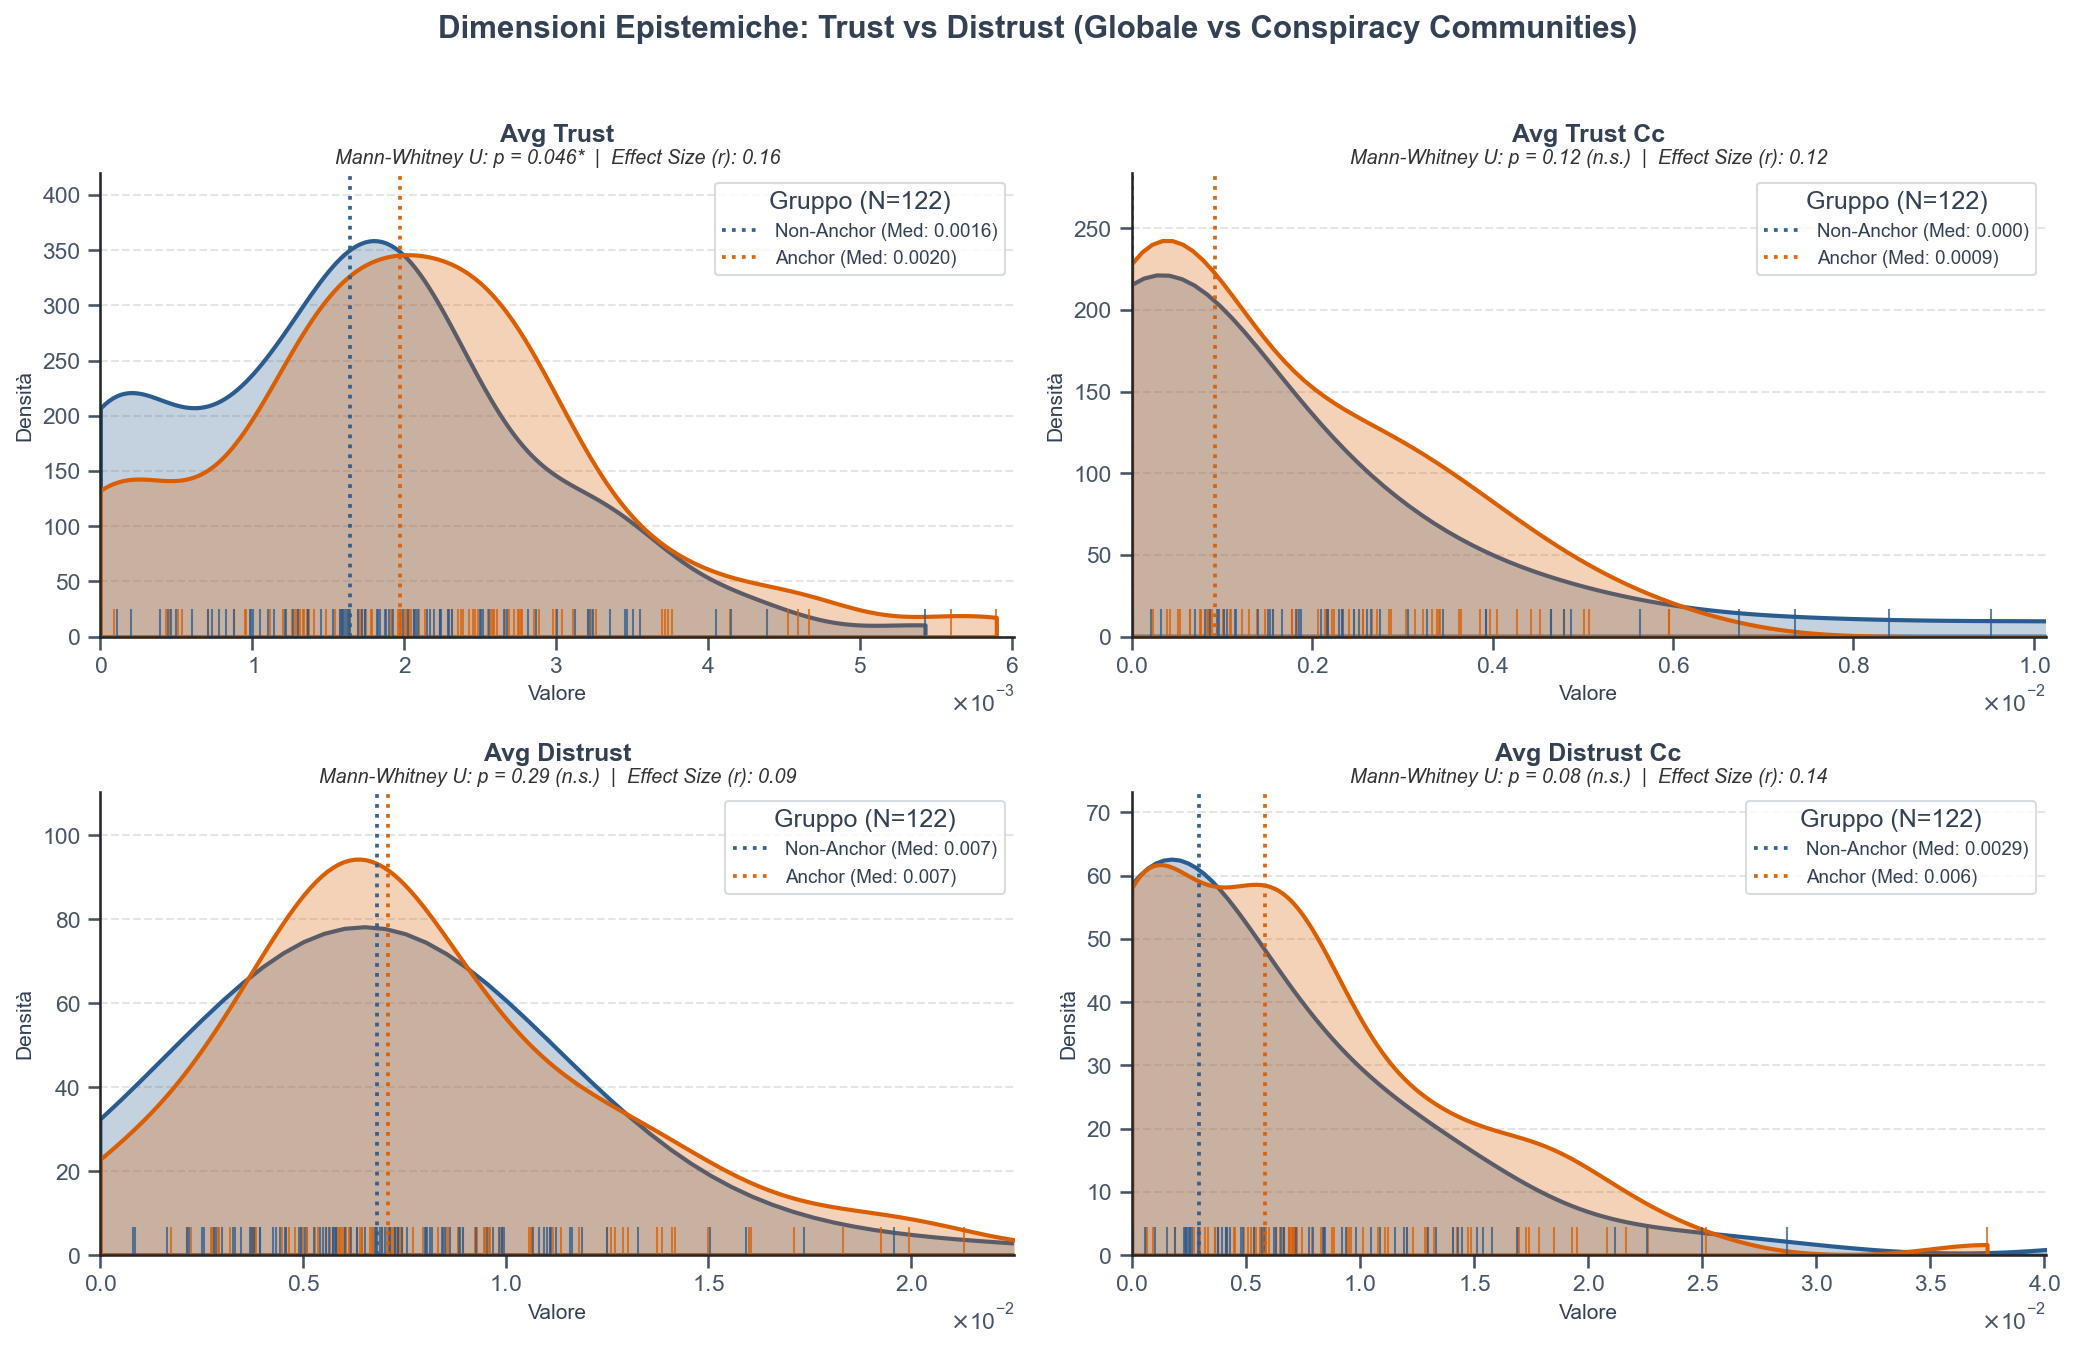

In [70]:
features_trust_distrust = [
    "avg_trust",
    "avg_trust_cc",
    "avg_distrust",
    "avg_distrust_cc",
]

plot_feature_grid(
    df=df,
    features=features_trust_distrust,
    title_group="Dimensioni Epistemiche: Trust vs Distrust (Globale vs Conspiracy Communities)",
    n_cols=2,
)

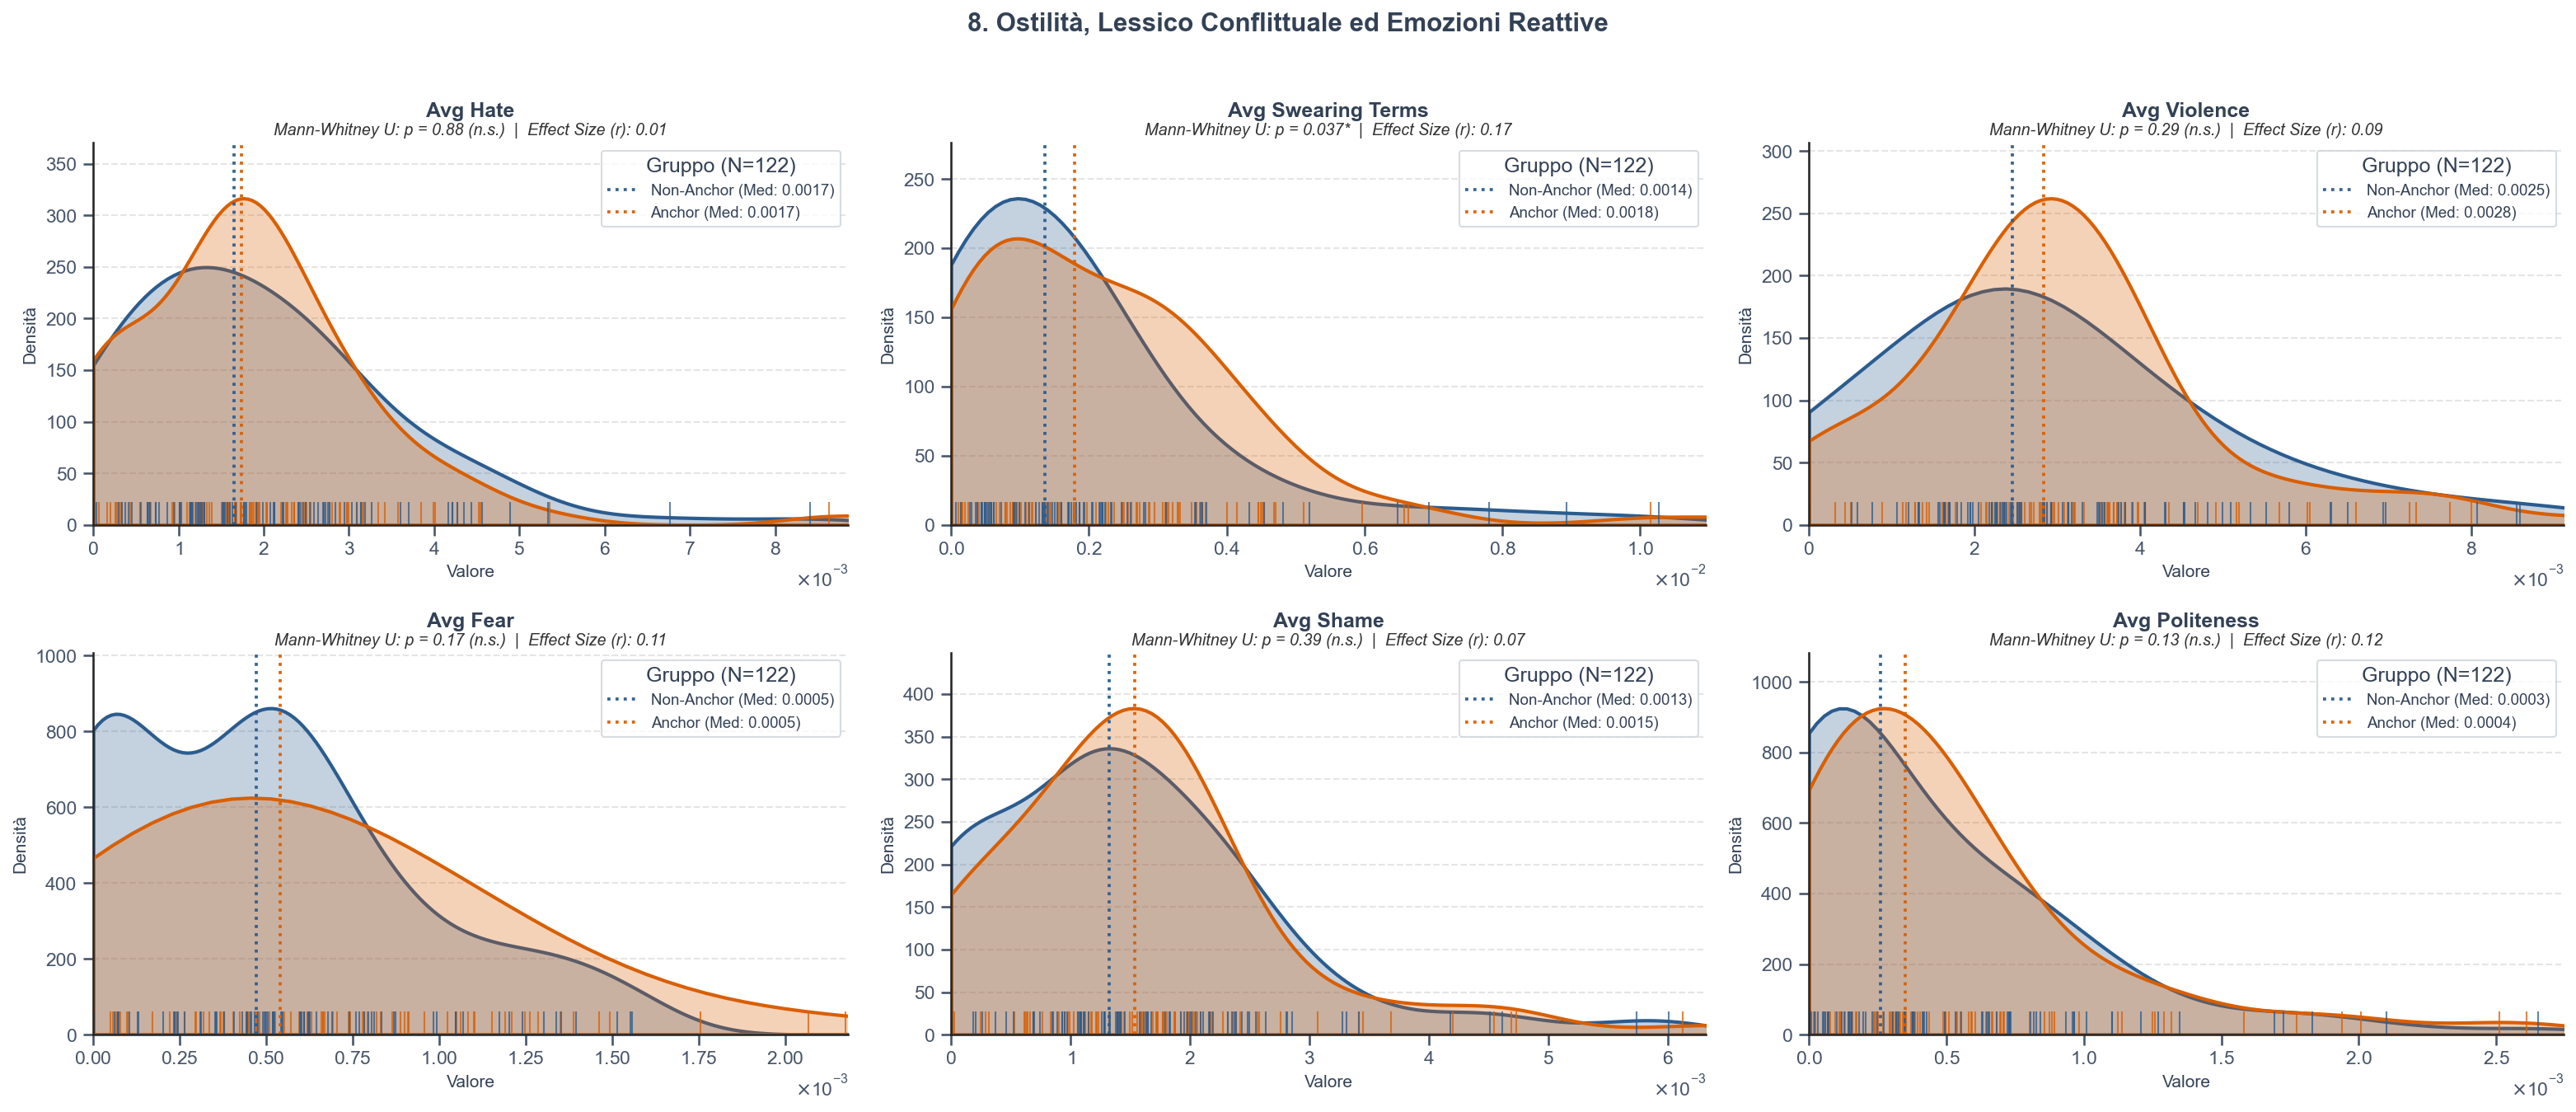

In [71]:
features_hostility_affect = [
    "avg_hate",
    "avg_swearing_terms",
    "avg_violence",
    "avg_fear",
    "avg_shame",
    "avg_politeness",
]

plot_feature_grid(
    df=df,
    features=features_hostility_affect,
    title_group="8. Ostilità, Lessico Conflittuale ed Emozioni Reattive",
    n_cols=3,
)

In [72]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
import seaborn as sns

# ==============================================================================
# PRESENTATION THEME & AESTHETIC CONFIGURATION
# ==============================================================================
sns.set_theme(style="ticks")
plt.rcParams.update(
    {
        "figure.facecolor": "#FFFFFF",
        "axes.facecolor": "#FFFFFF",
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "text.color": "#334155",
        "axes.labelcolor": "#334155",
        "xtick.color": "#475569",
        "ytick.color": "#475569",
    }
)

# Palette coordinata con la presentazione: Blu Navy (#1E3A8A) e Rosso Cremisi (#E11D48)
PALETTE = {
    "Non-Anchor": "#1E3A8A",
    "Anchor": "#E11D48",
}

# 1. Feature ordinate per la Slide 6 (4 Generiche a sinistra, 4 Specifiche a destra)
FEATURES_SLIDE_6 = [
    "total_contributions_obs",
    "posting_ratio",
    "moderated_ratio",
    "growing_exclusivity_contributions",
    "ratio_interactions_cc",
    "conspiracy_similarity",
    "empath_negative_emotion_cc",
    "avg_linguistic_coordination_cc",
]

# Dizionario per etichette pulite e leggibili sull'asse X
LABEL_MAP = {
    "total_contributions_obs": "Activity Volume (90d)",
    "posting_ratio": "Posting Ratio",
    "moderated_ratio": "Moderated Ratio",
    "growing_exclusivity_contributions": "Growing Exclusivity (ΔG)",
    "ratio_interactions_cc": "CC Interactions Ratio",
    "conspiracy_similarity": "Semantic Similarity (S-BERT)",
    "empath_negative_emotion_cc": "Negative Affect in CC",
    "avg_linguistic_coordination_cc": "CC Linguistic Coord.",
}


def plot_bivariate_multivariate_profile(
    df,
    features,
    title="",
    sort_by_significance=False,
    figsize=(12, 5.5),
    save_path="slide6_twin_contrast_profile.png",
):
    """Genera un unico plot multivariato di confronto bivariato (Stile Presentazione):

    - X: Feature selezionate (Ordinate per coerenza con lo script)
    - Y: Punteggio standardizzato (Z-Score) con CI 95%
    - Hue: Anchor (#E11D48) vs Non-Anchor (#1E3A8A)
    - Tratteggio verticale divisorio tra tratti eliminati e precursori sopravvissuti
    """
    plot_df = df.copy()

    # Gestione sicura del raggruppamento binario
    if "group_label" not in plot_df.columns:
        is_anchor_clean = (
            plot_df["is_anchor"]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "t"])
        )
        plot_df["group_label"] = np.where(
            is_anchor_clean, "Anchor", "Non-Anchor"
        )
    else:
        plot_df["group_label"] = plot_df["group_label"].replace(
            {"Candidate": "Non-Anchor"}
        )

    # Alias automatici per evitare KeyError
    if (
        "subreddit_obs_conspiracy_score" not in plot_df.columns
        and "subreddits_obs_conspiracy_score" in plot_df.columns
    ):
        plot_df["subreddit_obs_conspiracy_score"] = plot_df[
            "subreddits_obs_conspiracy_score"
        ]
    if (
        "growing_exclusibity_contributions" not in plot_df.columns
        and "growing_exclusivity_contributions" in plot_df.columns
    ):
        plot_df["growing_exclusibity_contributions"] = plot_df[
            "growing_exclusivity_contributions"
        ]

    valid_features = [f for f in features if f in plot_df.columns]
    if not valid_features:
        print("Nessuna delle feature specificate è presente nel DataFrame.")
        return

    # Calcolo statistiche standardizzate e test per ciascuna feature
    records = []
    for feat in valid_features:
        s = plot_df[feat].dropna()
        if s.std() == 0 or len(s) == 0:
            continue

        # Standardizzazione Z-Score sull'intero dataset per confrontare la metrica
        z = (plot_df[feat] - s.mean()) / s.std()

        z_non = z[plot_df["group_label"] == "Non-Anchor"].dropna()
        z_anc = z[plot_df["group_label"] == "Anchor"].dropna()

        # Test non parametrico di Mann-Whitney U sui dati effettivi
        u_stat, p_val = mannwhitneyu(
            plot_df[plot_df["group_label"] == "Anchor"][feat].dropna(),
            plot_df[plot_df["group_label"] == "Non-Anchor"][feat].dropna(),
            alternative="two-sided",
        )

        clean_name = LABEL_MAP.get(feat, feat.replace("_", " ").title())

        records.append(
            {
                "feature": feat,
                "clean_label": clean_name,
                "mean_non": z_non.mean(),
                "ci_non": 1.96 * z_non.sem(),
                "mean_anc": z_anc.mean(),
                "ci_anc": 1.96 * z_anc.sem(),
                "p_val": p_val,
                "is_sig": p_val < 0.05,
            }
        )

    res_df = pd.DataFrame(records)
    if sort_by_significance:
        res_df = res_df.sort_values(
            by=["is_sig", "p_val"], ascending=[False, True]
        ).reset_index(drop=True)

    # Costruzione del grafico (Alta risoluzione 300 DPI)
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    x_pos = np.arange(len(res_df))
    width = 0.22  # Distanza orizzontale tra punto Anchor e Non-Anchor

    # Griglia orizzontale pulita e discreta
    ax.grid(
        axis="y",
        color="#E2E8F0",
        linestyle="-",
        linewidth=1.0,
        alpha=0.85,
        zorder=0,
    )
    ax.set_axisbelow(True)

    # Linea orizzontale di riferimento a Z = 0 (media campionaria globale)
    ax.axhline(
        0, color="#94A3B8", linestyle="--", linewidth=1.2, alpha=0.85, zorder=1
    )

    # Linea verticale divisoria tra tratti generici (sinistra) e precursori (destra)
    ax.axvline(3.5, color="#CBD5E1", linestyle="--", linewidth=1.5, zorder=1)

    for i, row in res_df.iterrows():
        is_sig = row["is_sig"]

        # Parametri visivi: attenuazione decisa se non significativo
        alpha_val = 1.0 if is_sig else 0.28
        marker_non = "o" if is_sig else "X"
        marker_anc = "s" if is_sig else "X"
        marker_size = 8.5 if is_sig else 7.0
        err_lw = 2.0 if is_sig else 1.1

        # Traccia uno stem tratteggiato verticale che evidenzia il divario (gap) tra i due gruppi
        stem_color = "#475569" if is_sig else "#CBD5E1"
        ax.plot(
            [i, i],
            [row["mean_non"], row["mean_anc"]],
            color=stem_color,
            linestyle=":",
            alpha=alpha_val,
            lw=1.8 if is_sig else 1.0,
            zorder=2,
        )

        # Stima Non-Anchor (Blu Navy) con barre di errore CI 95%
        ax.errorbar(
            i - width / 2,
            row["mean_non"],
            yerr=row["ci_non"],
            fmt=marker_non,
            color=PALETTE["Non-Anchor"],
            alpha=alpha_val,
            markersize=marker_size,
            capsize=3.5,
            capthick=1.3,
            elinewidth=err_lw,
            zorder=3,
        )

        # Stima Anchor (Rosso Cremisi) con barre di errore CI 95%
        ax.errorbar(
            i + width / 2,
            row["mean_anc"],
            yerr=row["ci_anc"],
            fmt=marker_anc,
            color=PALETTE["Anchor"],
            alpha=alpha_val,
            markersize=marker_size,
            capsize=3.5,
            capthick=1.3,
            elinewidth=err_lw,
            zorder=3,
        )

        # Asterischi di significatività posizionati sopra il valore massimo
        if is_sig:
            p = row["p_val"]
            stars = "***" if p < 0.001 else ("**" if p < 0.01 else "*")
            max_y = max(
                row["mean_non"] + row["ci_non"], row["mean_anc"] + row["ci_anc"]
            )
            ax.text(
                i,
                max_y + 0.08,
                stars,
                ha="center",
                va="bottom",
                fontsize=12,
                fontweight="bold",
                color="#1E293B",
            )

    # Etichette asse X ruotate per massima leggibilità
    ax.set_xticks(x_pos)
    ax.set_xticklabels(
        res_df["clean_label"],
        rotation=30,
        ha="right",
        fontsize=9.5,
        fontweight="bold",
        color="#334155",
    )
    ax.set_ylabel(
        "Standardized Score (Z-Score)",
        fontsize=11.5,
        fontweight="bold",
        color="#334155",
        labelpad=10,
    )
    ax.set_title(
        title, fontsize=13, fontweight="bold", color="#1E293B", pad=16
    )
    ax.tick_params(axis="y", which="major", labelsize=10.5, colors="#475569")

    # Margine superiore extra per evitare collisioni tra asterischi e legenda
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax + 0.32)

    # Legenda accademica in inglese e ripulita dai riferimenti ad Alpha
    n_anc = (plot_df["group_label"] == "Anchor").sum()
    n_non = (plot_df["group_label"] == "Non-Anchor").sum()

    legend_items = [
        Line2D(
            [0],
            [0],
            marker="s",
            color="w",
            markerfacecolor=PALETTE["Anchor"],
            markersize=8.5,
            label=f"Anchor (N={n_anc})",
        ),
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor=PALETTE["Non-Anchor"],
            markersize=8.5,
            label=f"Non-Anchor (N={n_non})",
        ),
        Line2D(
            [0],
            [0],
            marker="o",
            color="#334155",
            markersize=8,
            linestyle="None",
            label="Significant ($p < 0.05$)",
        ),
        Line2D(
            [0],
            [0],
            marker="X",
            color="#94A3B8",
            alpha=0.55,
            markersize=7.5,
            linestyle="None",
            label=r"Not Significant ($p \geq 0.05$)",
        ),
    ]
    ax.legend(
        handles=legend_items,
        loc="upper right",
        frameon=True,
        facecolor="#FFFFFF",
        edgecolor="#CBD5E1",
        fontsize=9,
    )

    sns.despine(ax=ax, top=True, right=True)
    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["bottom"].set_linewidth(1.2)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


# ==============================================================================
# ESEMPIO DI ESECUZIONE PER LA SLIDE 6
# ==============================================================================
# plot_bivariate_multivariate_profile(
#     df=df,
#     features=FEATURES_SLIDE_6,
#     sort_by_significance=False,
#     save_path="slide6_twin_contrast_profile.png"
# )

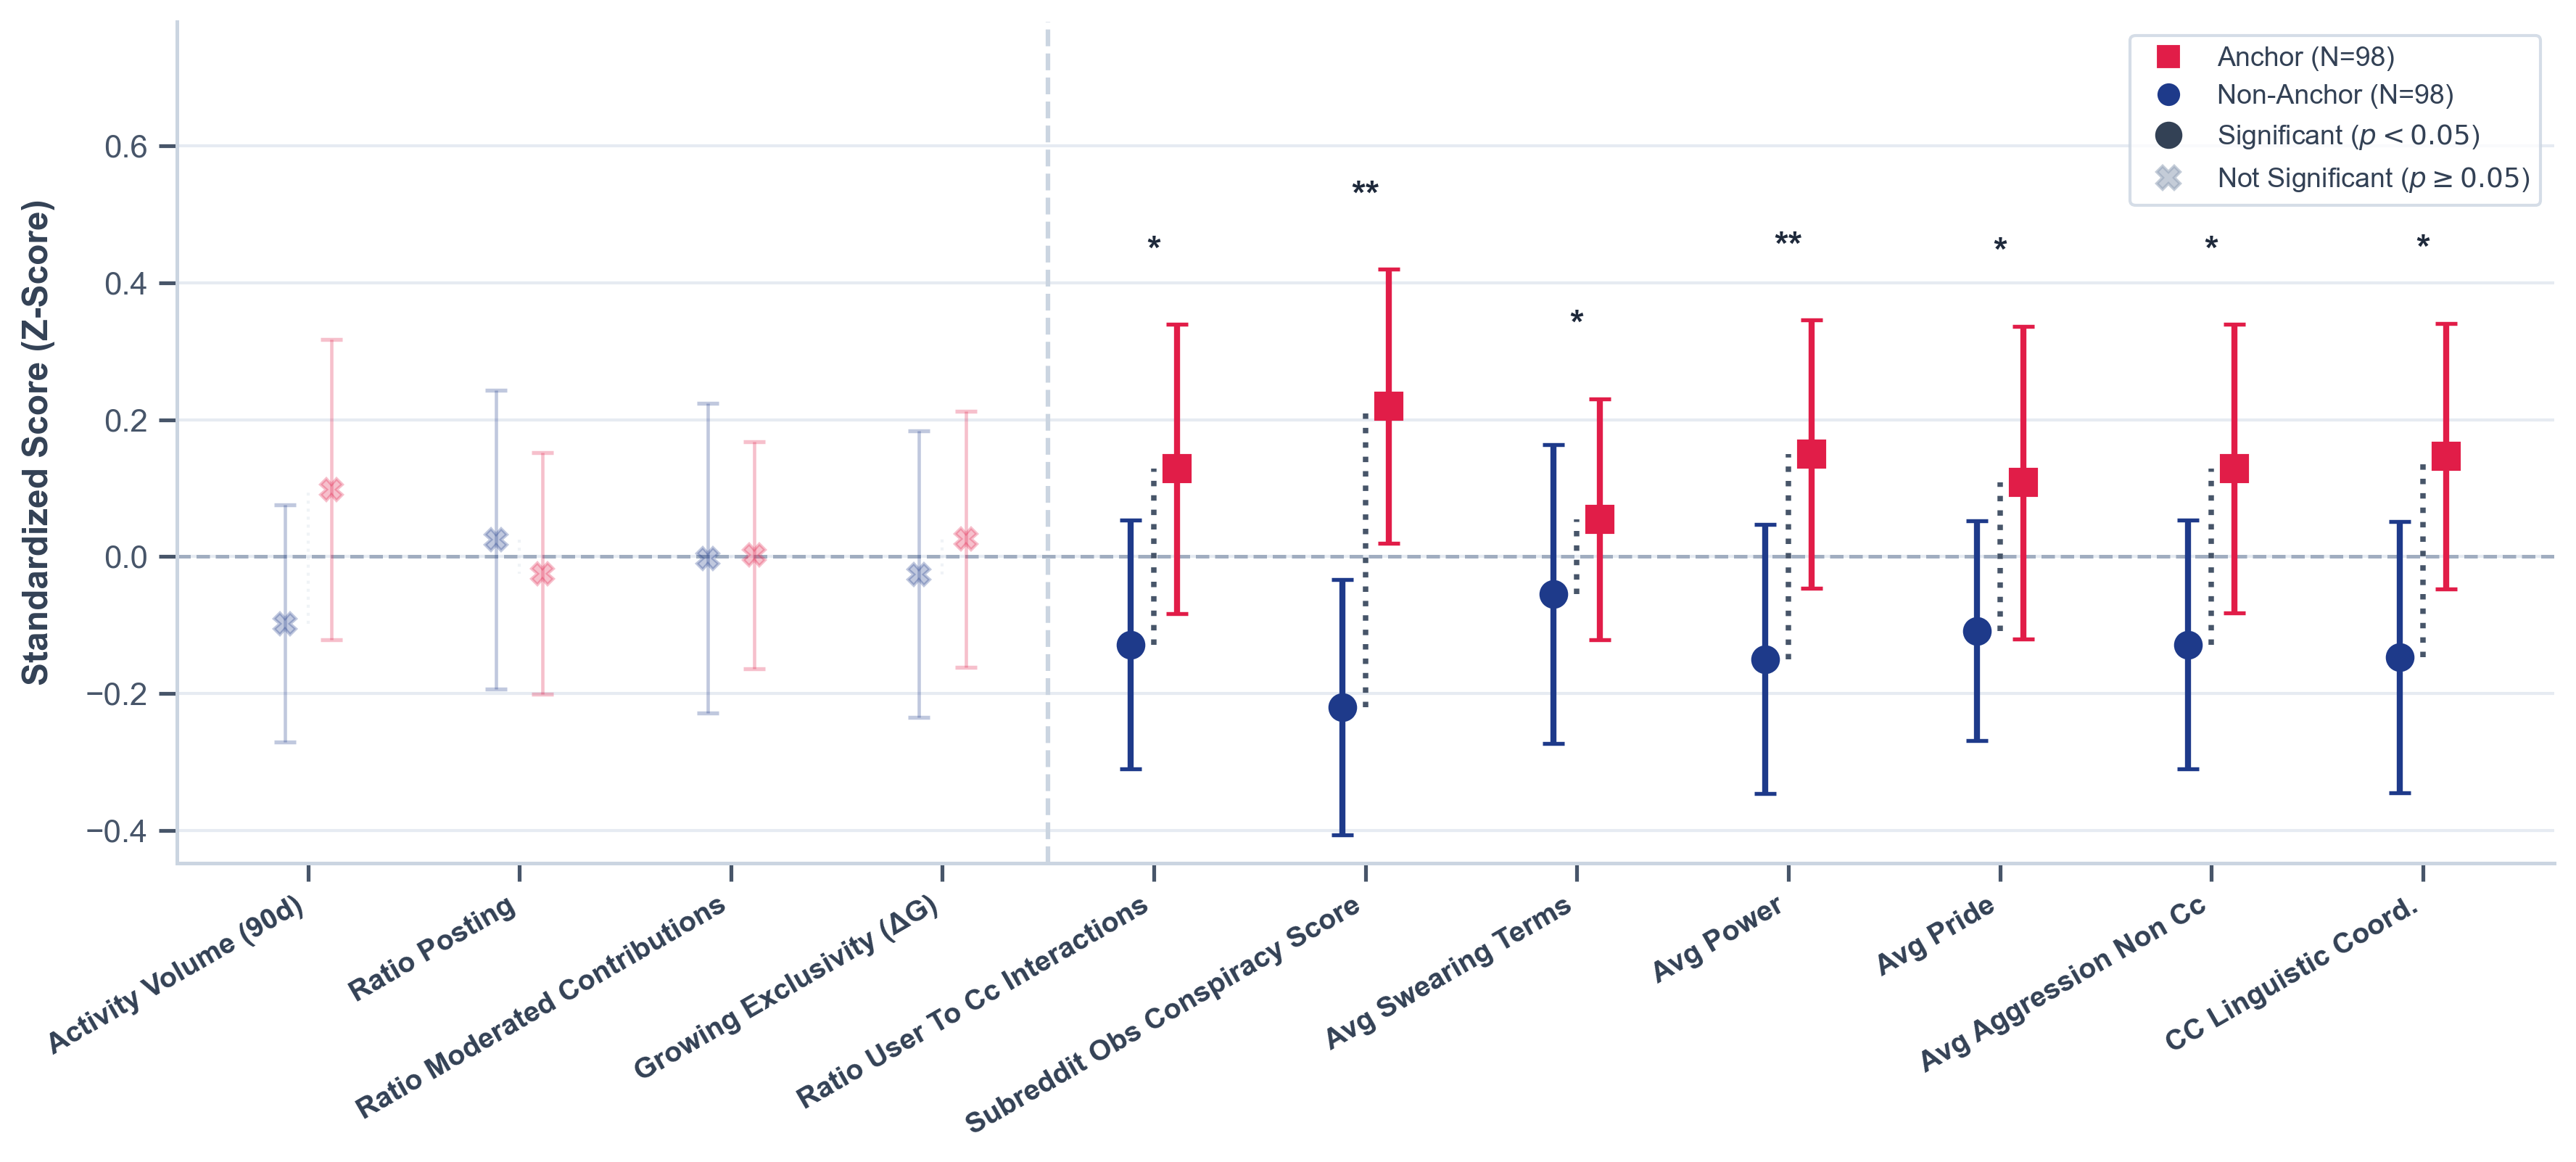

In [73]:
features_all = [
    "total_contributions_obs",
    "ratio_posting",
    "ratio_moderated_contributions",
    "growing_exclusivity_contributions",
    "ratio_user_to_cc_interactions",
    "subreddit_obs_conspiracy_score",
    "avg_swearing_terms",
    "avg_power",
    "avg_pride",
    "avg_aggression_non_cc",
    "avg_linguistic_coordination_cc"
]

# Esecuzione del plot bivariato multivariato
plot_bivariate_multivariate_profile(
    df=df,
    features=features_all,
    sort_by_significance=False,  # Se impostato su True, raggruppa le feature significative a sinistra
)

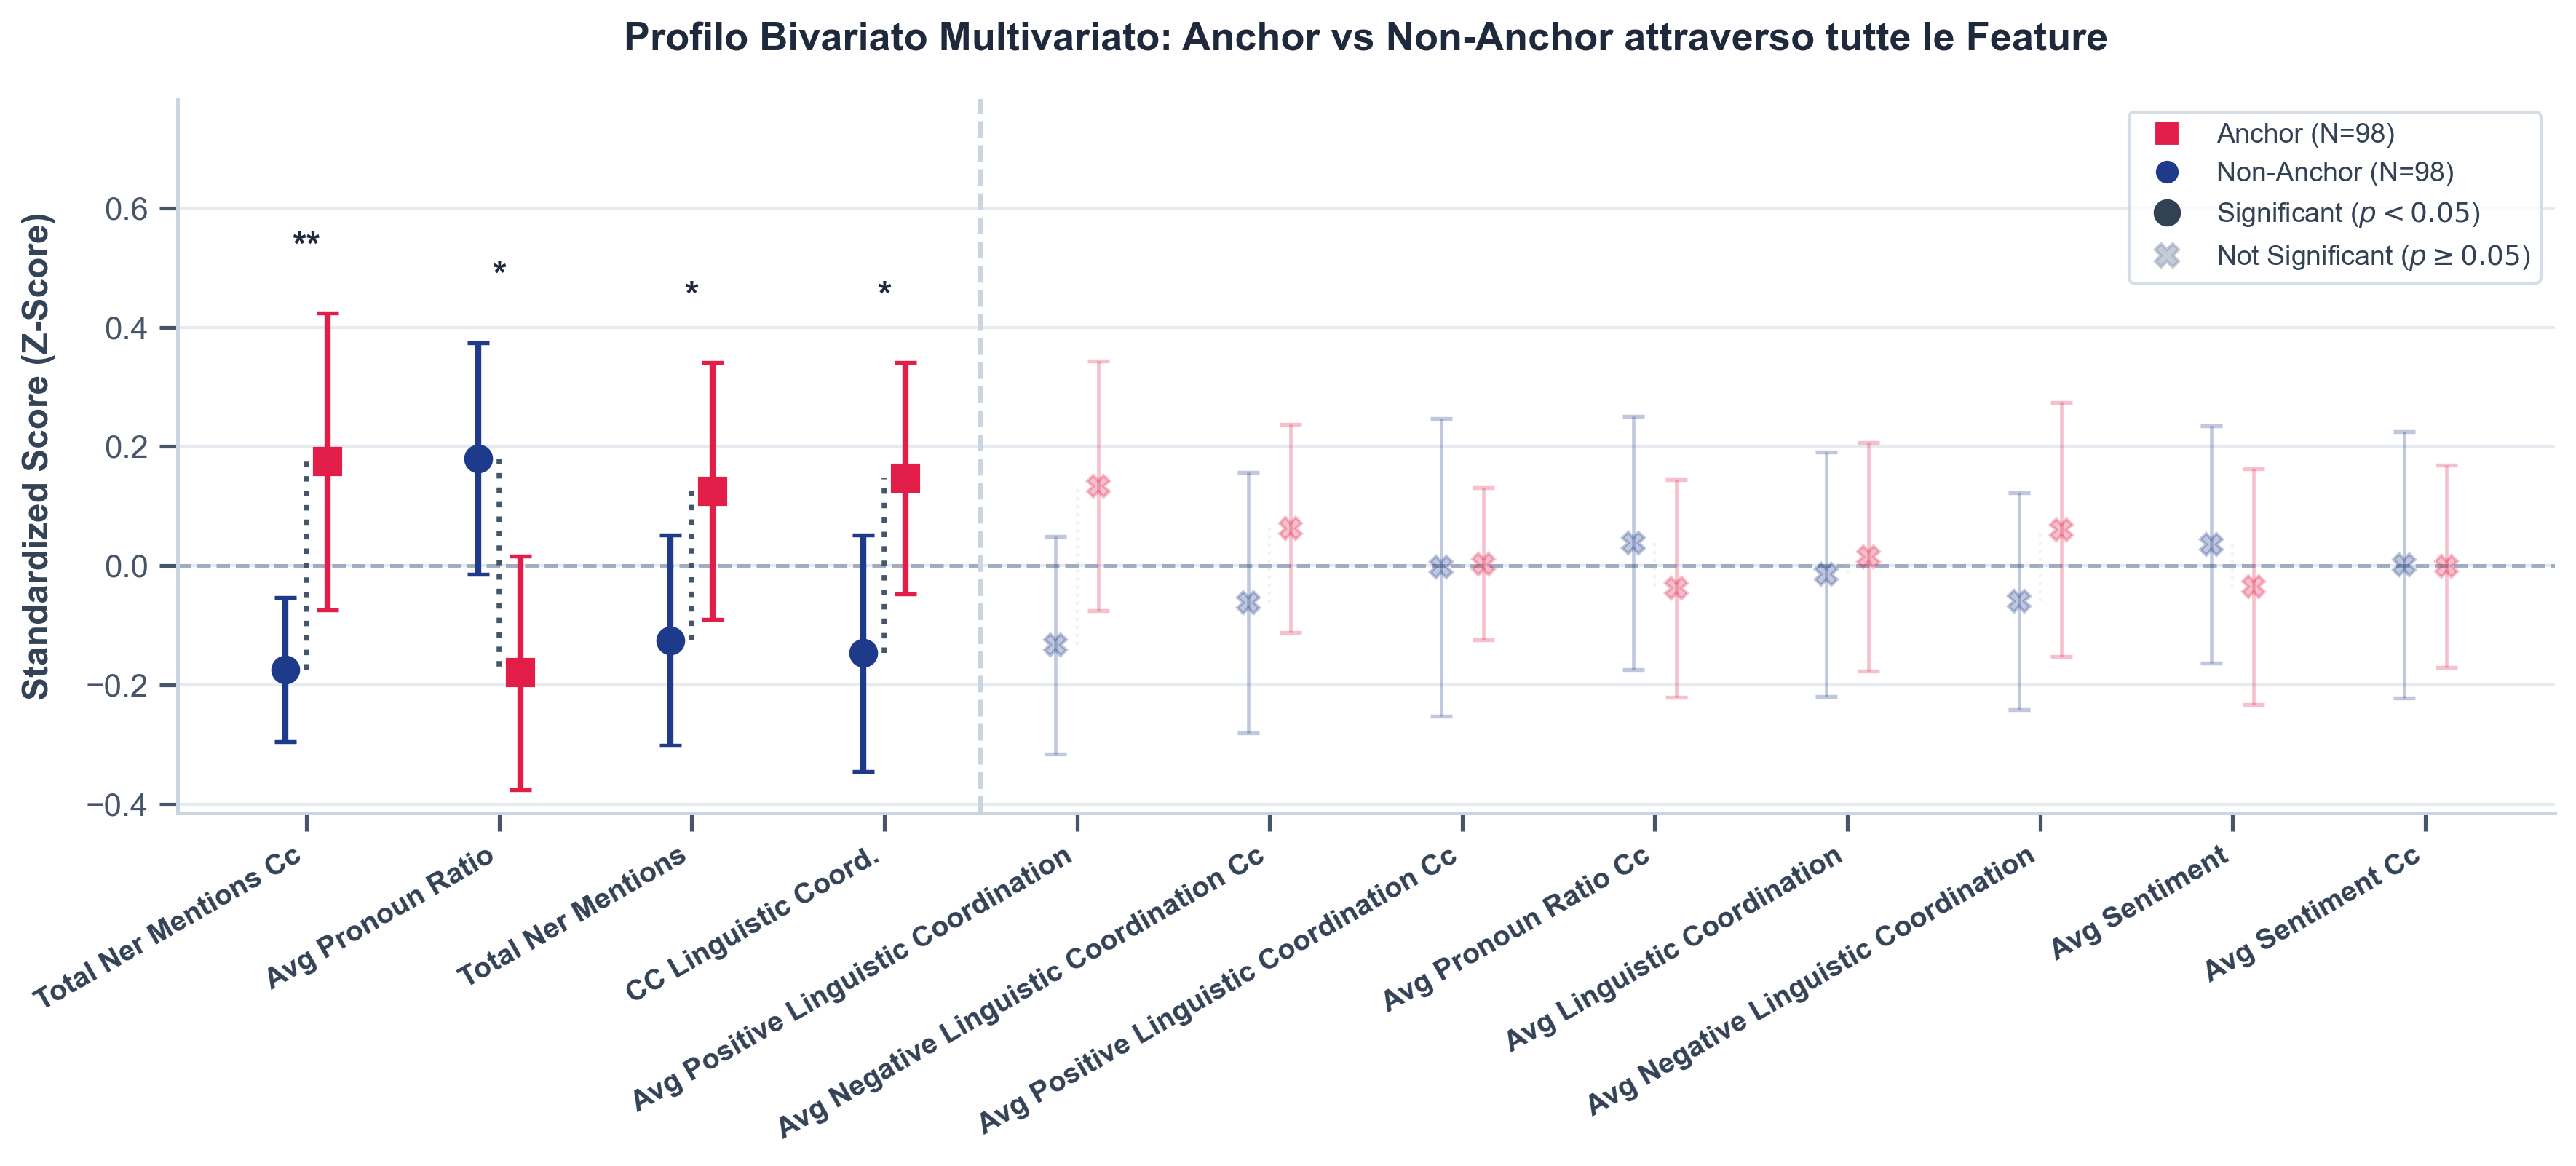

In [74]:
features_all = [
    "avg_linguistic_coordination",
    "avg_linguistic_coordination_cc",
    "avg_pronoun_ratio",
    "avg_pronoun_ratio_cc",
    "total_ner_mentions",
    "total_ner_mentions_cc",
    "avg_sentiment",
    "avg_sentiment_cc",
    "avg_positive_linguistic_coordination",
    "avg_positive_linguistic_coordination_cc",
    "avg_negative_linguistic_coordination",
    "avg_negative_linguistic_coordination_cc"
]

# Esecuzione del plot bivariato multivariato
plot_bivariate_multivariate_profile(
    df=df,
    features=features_all,
    title="Profilo Bivariato Multivariato: Anchor vs Non-Anchor attraverso tutte le Feature",
    sort_by_significance=True) # Se impostato su True, raggruppa le feature significative a sinistra

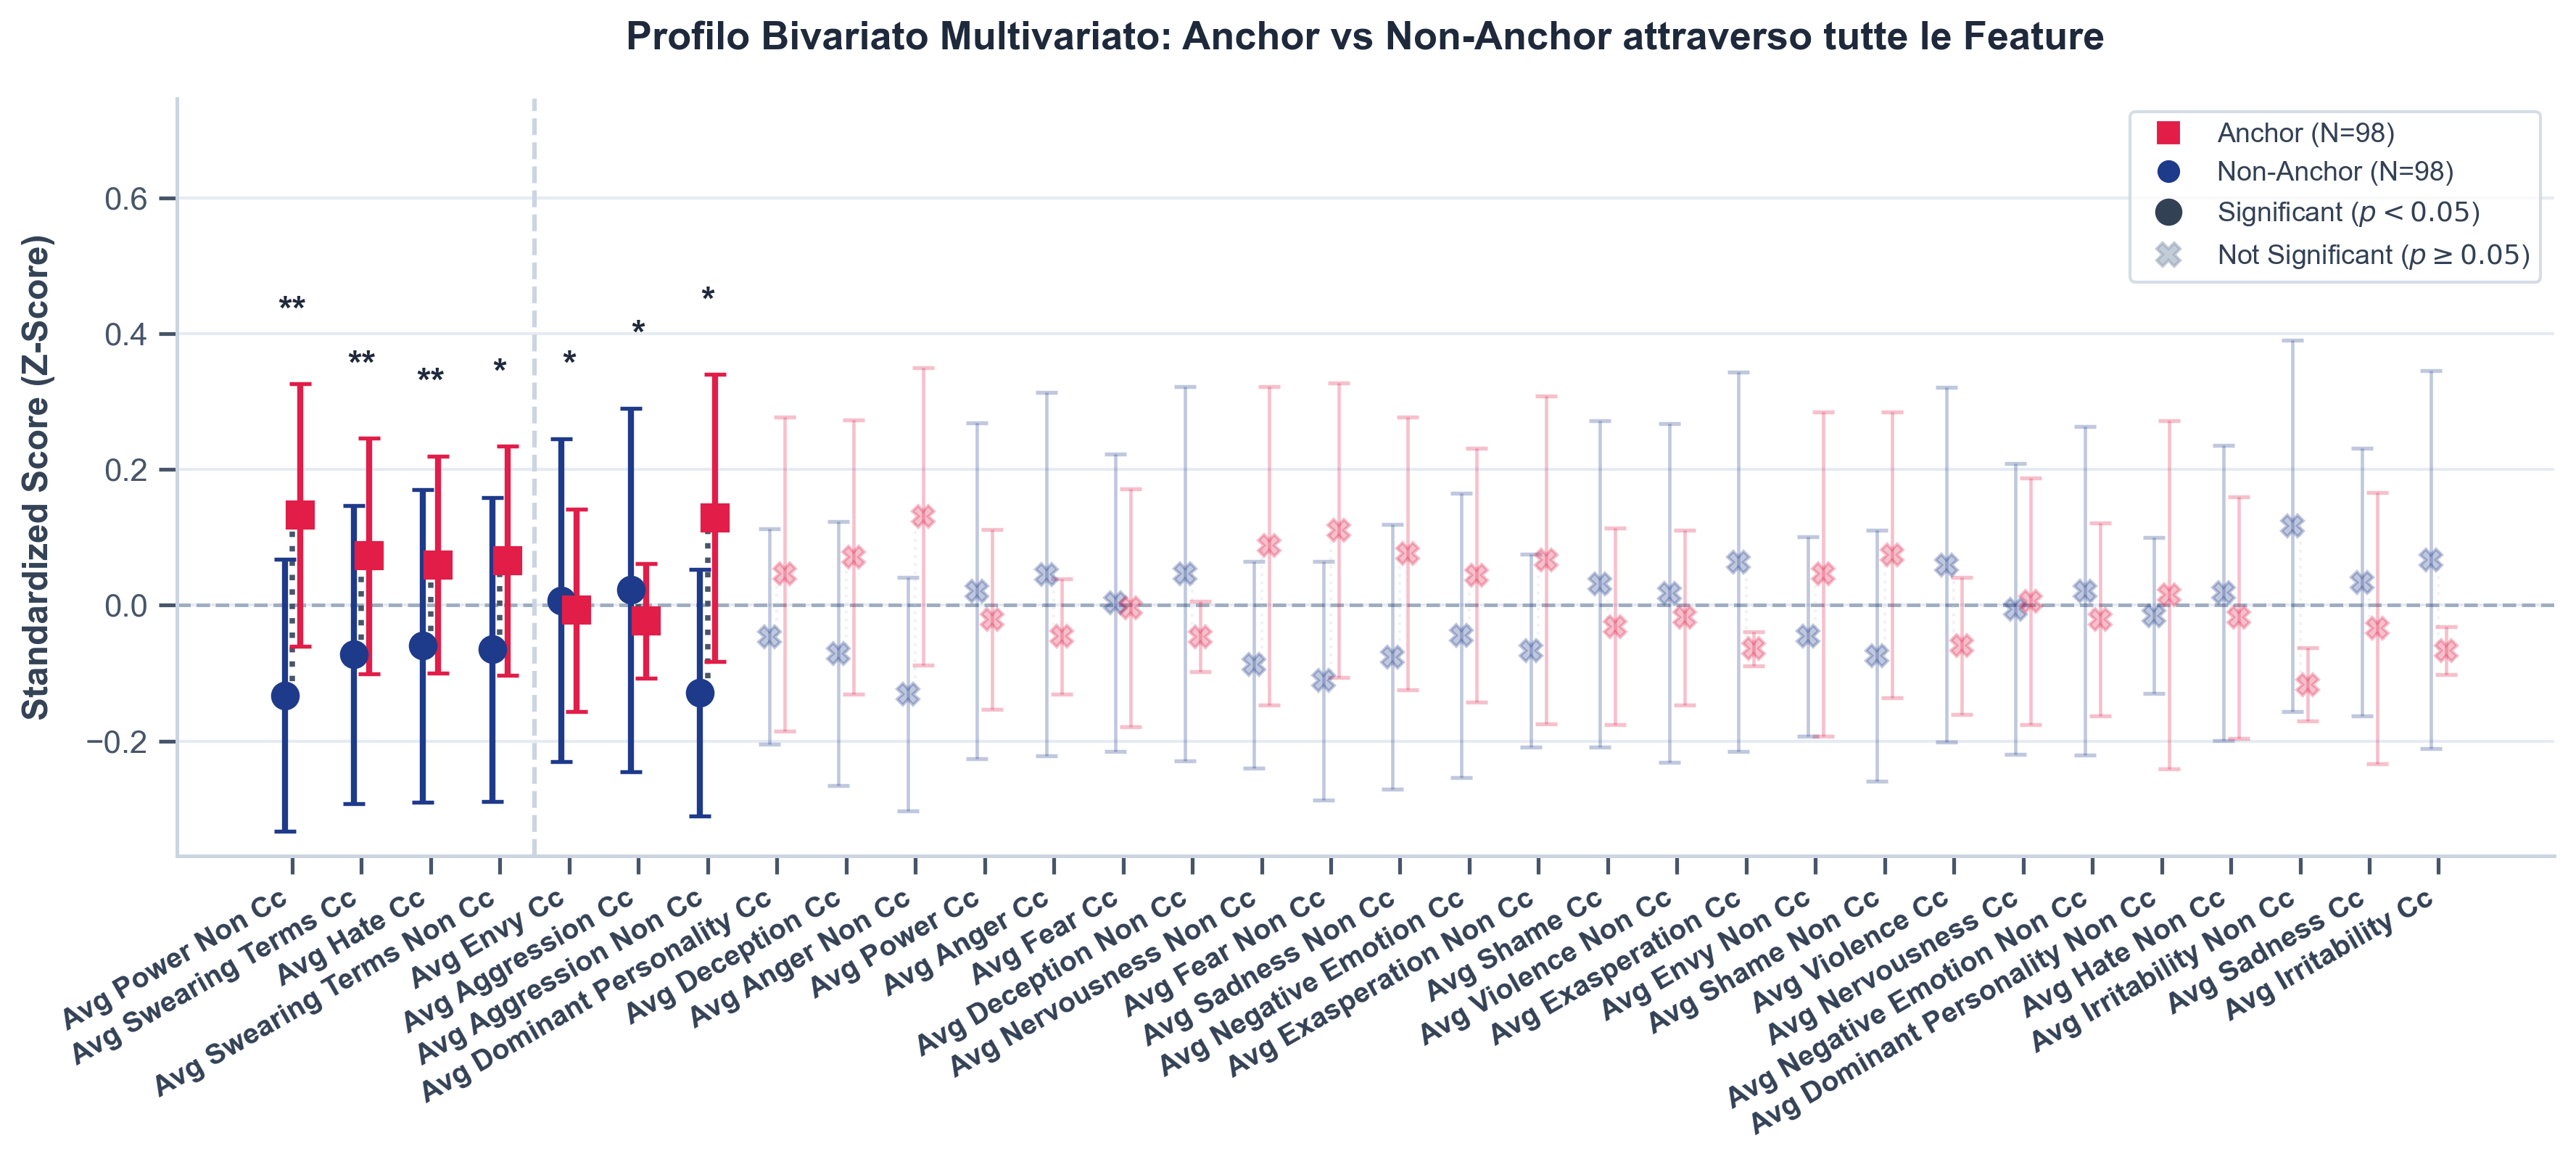

In [75]:
features_all = [
    "avg_fear_non_cc",
    "avg_fear_cc",
    "avg_violence_non_cc",
    "avg_violence_cc",
    "avg_power_non_cc",
    "avg_power_cc",
    "avg_deception_non_cc",
    "avg_deception_cc",
    "avg_anger_non_cc",
    "avg_anger_cc",
    "avg_sadness_non_cc",
    "avg_sadness_cc",
    "avg_nervousness_non_cc",
    "avg_nervousness_cc",
    "avg_dominant_personality_non_cc",
    "avg_dominant_personality_cc",
    "avg_shame_non_cc",
    "avg_shame_cc",
    "avg_irritability_non_cc",
    "avg_irritability_cc",
    "avg_negative_emotion_non_cc",
    "avg_negative_emotion_cc",
    "avg_aggression_non_cc",
    "avg_aggression_cc",
    "avg_hate_non_cc",
    "avg_hate_cc",
    "avg_swearing_terms_non_cc",
    "avg_swearing_terms_cc",
    "avg_envy_non_cc",
    "avg_envy_cc",
    "avg_exasperation_non_cc",
    "avg_exasperation_cc"
]

# Esecuzione del plot bivariato multivariato
plot_bivariate_multivariate_profile(
    df=df,
    features=features_all,
    title="Profilo Bivariato Multivariato: Anchor vs Non-Anchor attraverso tutte le Feature",
    sort_by_significance=True) # Se impostato su True, raggruppa le feature significative a sinistra

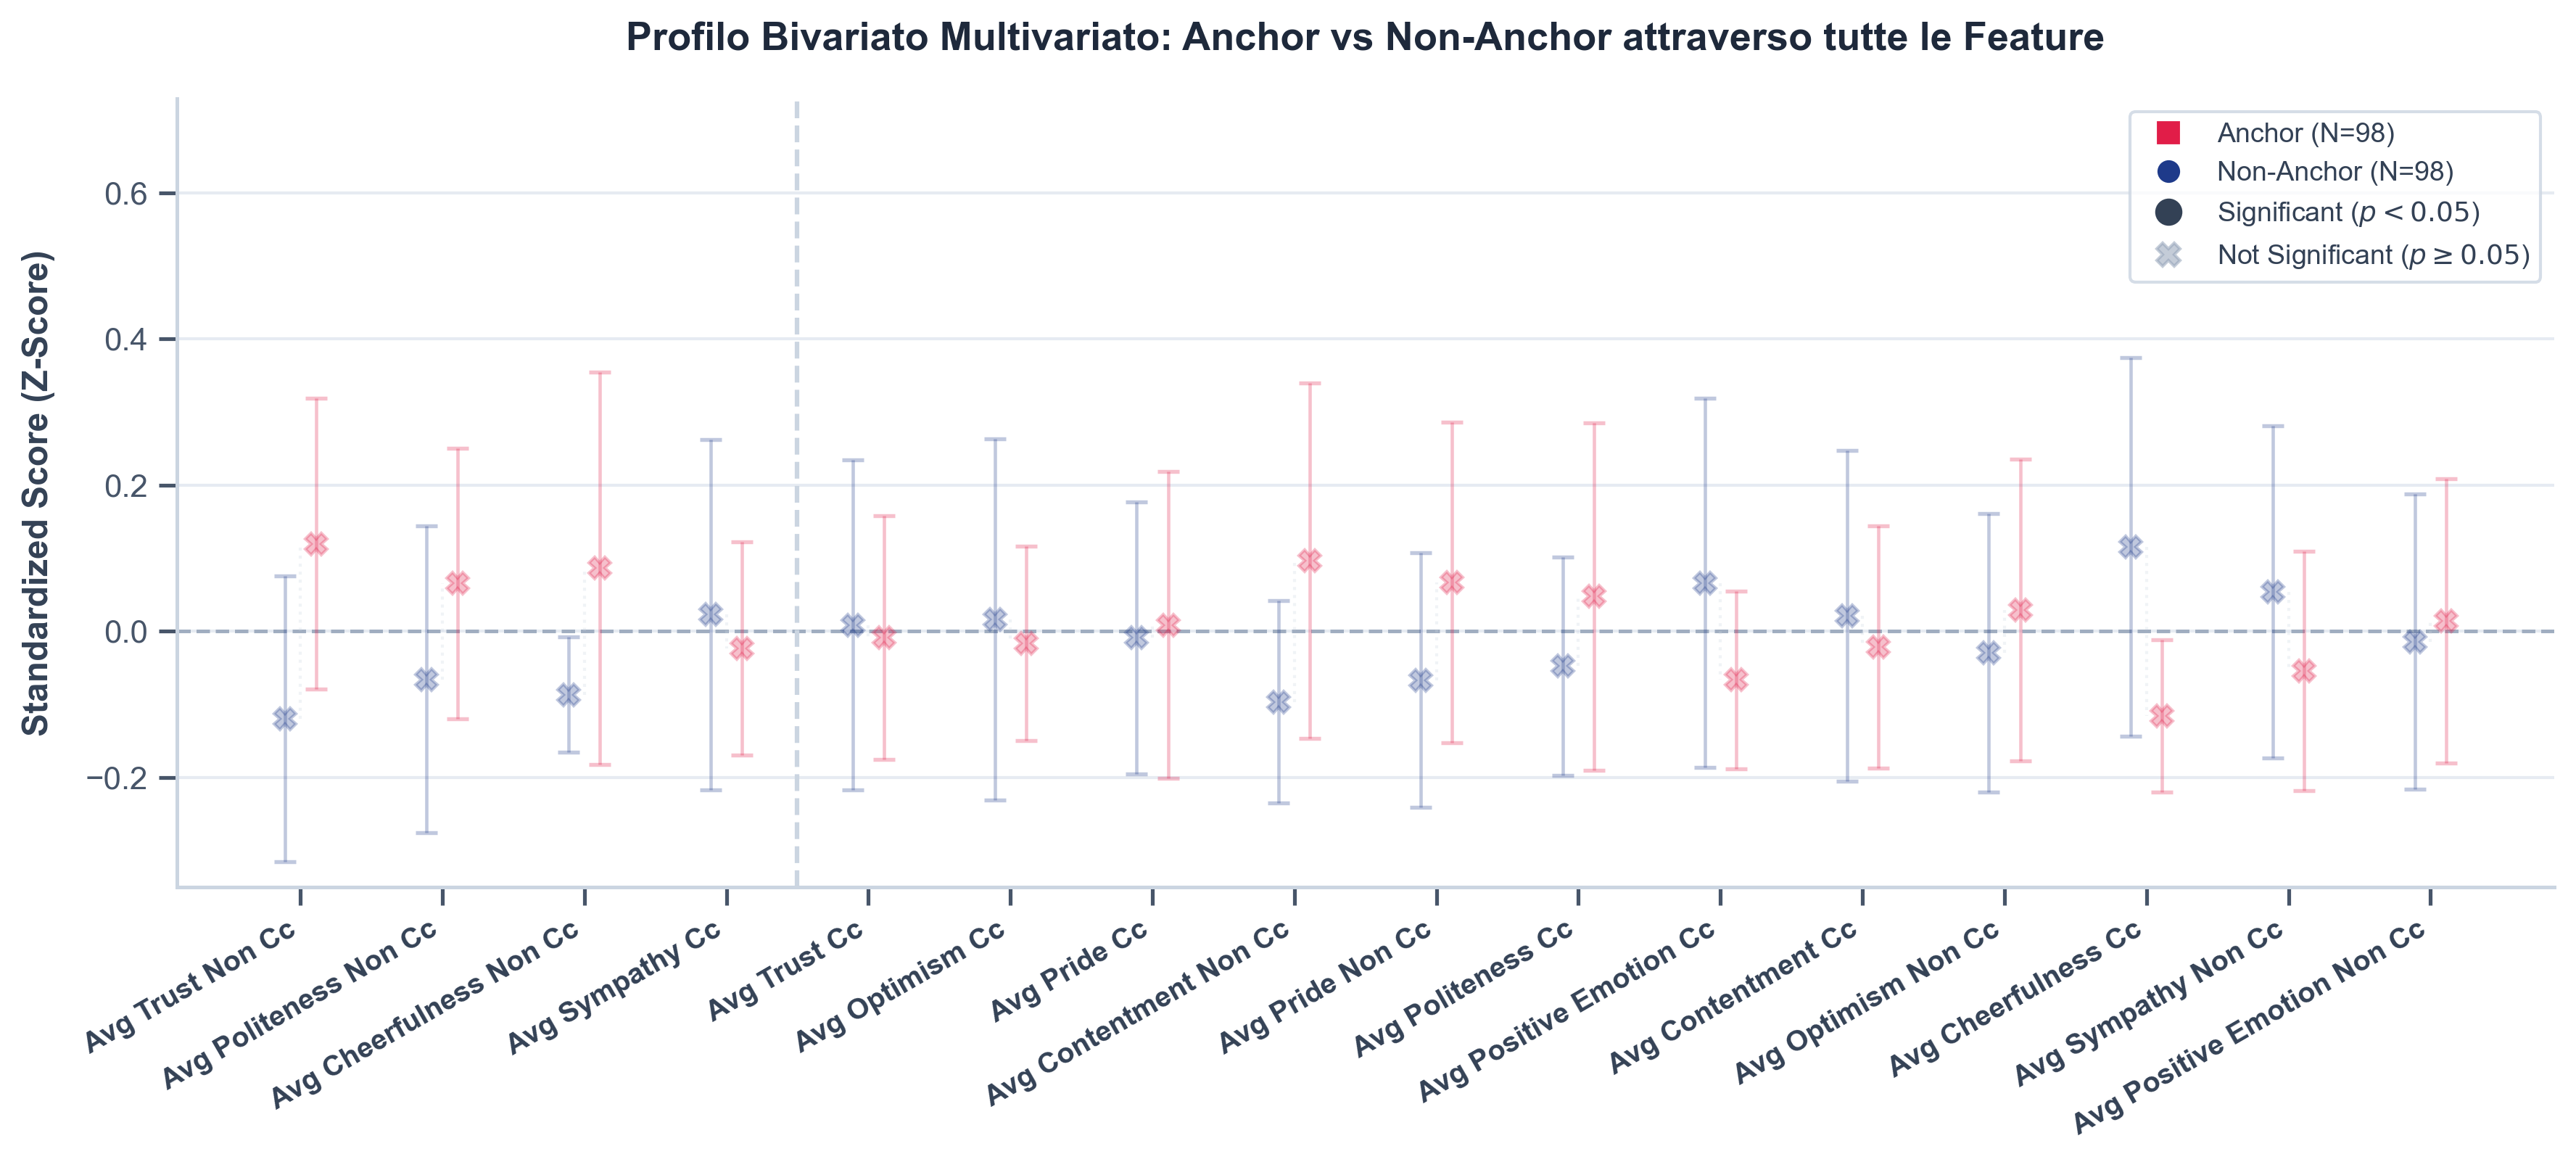

In [76]:
features_all = [
    "avg_pride_non_cc",
    "avg_pride_cc",
    "avg_optimism_non_cc",
    "avg_optimism_cc",
    "avg_trust_non_cc",
    "avg_trust_cc",
    "avg_politeness_non_cc",
    "avg_politeness_cc",
    "avg_sympathy_non_cc",
    "avg_sympathy_cc",
    "avg_cheerfulness_non_cc",
    "avg_cheerfulness_cc",
    "avg_contentment_non_cc",
    "avg_contentment_cc",
    "avg_positive_emotion_non_cc",
    "avg_positive_emotion_cc",
]

# Esecuzione del plot bivariato multivariato
plot_bivariate_multivariate_profile(
    df=df,
    features=features_all,
    title="Profilo Bivariato Multivariato: Anchor vs Non-Anchor attraverso tutte le Feature",
    sort_by_significance=True) # Se impostato su True, raggruppa le feature significative a sinistra

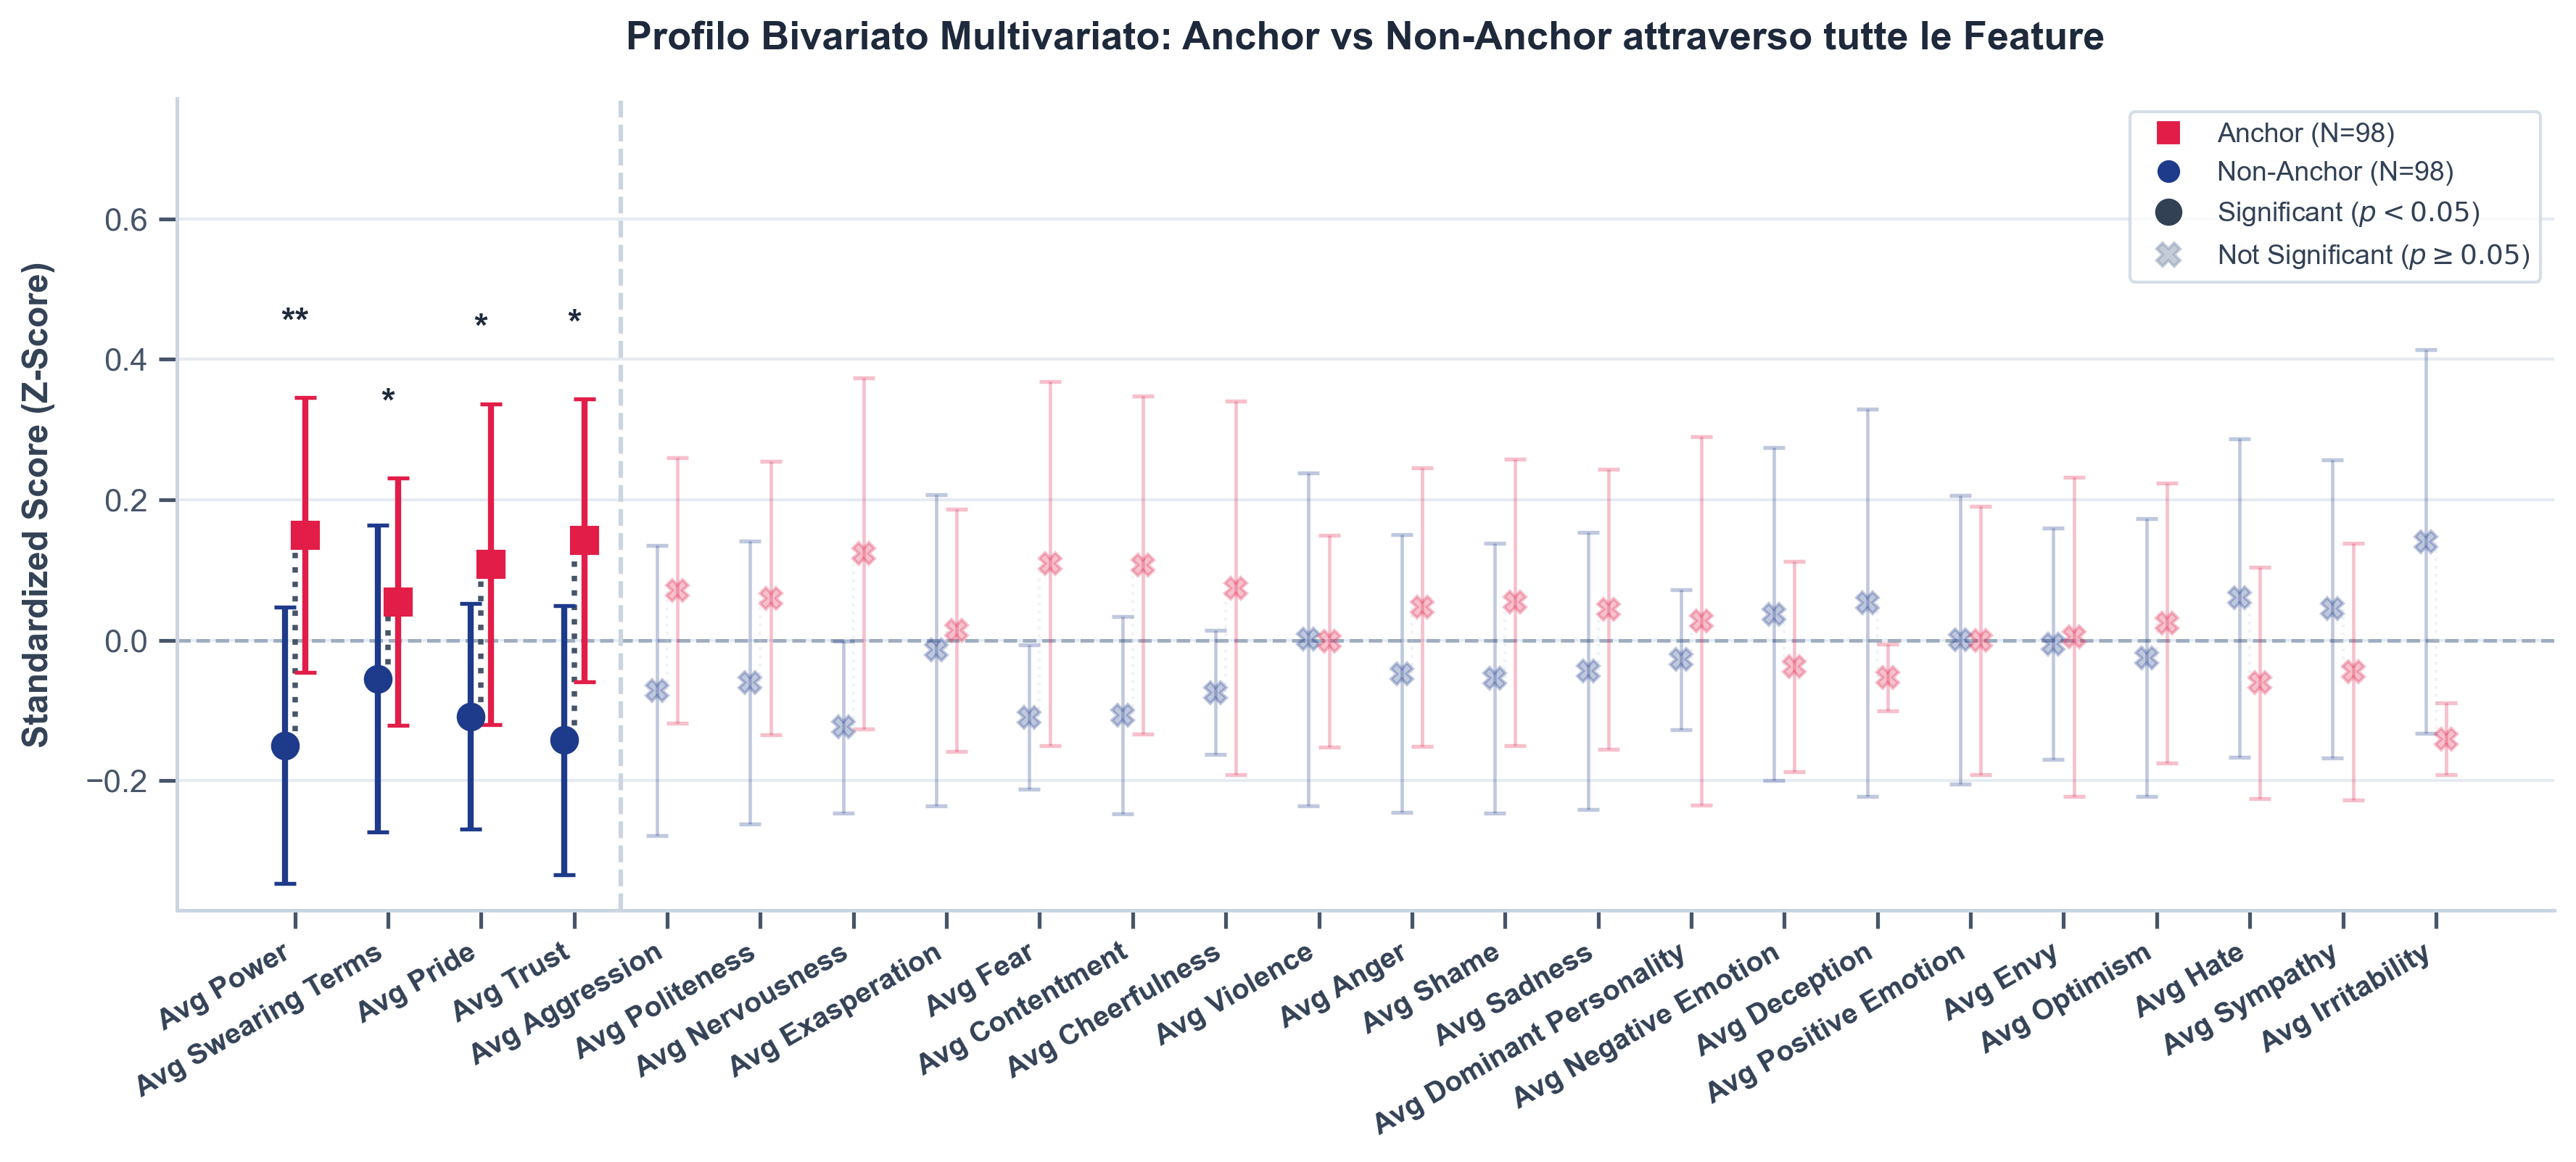

In [77]:
features_all = [
    "avg_pride",
    "avg_optimism",
    "avg_trust",
    "avg_politeness",
    "avg_sympathy",
    "avg_cheerfulness",
    "avg_contentment",
    "avg_positive_emotion",
    "avg_fear",
    "avg_violence",
    "avg_power",
    "avg_deception",
    "avg_anger",
    "avg_sadness",
    "avg_nervousness",
    "avg_dominant_personality",
    "avg_shame",
    "avg_irritability",
    "avg_negative_emotion",
    "avg_aggression",
    "avg_hate",
    "avg_swearing_terms",
    "avg_envy",
    "avg_exasperation",
]

# Esecuzione del plot bivariato multivariato
plot_bivariate_multivariate_profile(
    df=df,
    features=features_all,
    title="Profilo Bivariato Multivariato: Anchor vs Non-Anchor attraverso tutte le Feature",
    sort_by_significance=True) # Se impostato su True, raggruppa le feature significative a sinistra